# Zomato Dataset EDA with Unsupervised Machine Learning

## Project Type:
Explolatory Data Analysis + Unsupervised Machine Learning (Clusturing)

## Project Focus:
1. Given Datasets:
  * Zomato Resturants names and Metadata.csv
  * Zomato Ressturant reviews.csv
2. Exploratory dataset analysis on each of these datasets
3. Combine these two seperate datasets into one
4. Detailed analysis of the merged dataset
5. Segment resturants with three unsupervised learning algorrithms (clusturing).  
6. Detailed analysis of the model comparison and business interpretation.

## Problem Statement:
The two given datasets provide us with the resturant metadata and review data. The task is to combine these sources, clean inconsistencies, analyse ratings and written feedback and discover groups of resturants with similar price, reviews, cuisines and other characteristics.

the project must answer the following questions:
1. What do ratings, review sentiment, cuisine mix, estimated cost per person, collections, and reviewer activity reveal about the supplied Hyderabad restaurant sample?
2. Is estimated cost associated with average restaurant rating? Does cuisine breadth appear related to rating? Do reviews with pictures have a different rating distribution?
3. Can restaurant-level attributes and review-derived signals be used to segment restaurants into actionable groups?
4. Which of K-Means, Agglomerative Clustering, and Gaussian Mixture Models gives the most useful balance of cluster separation, compactness, stability, interpretability, and practical assignability?

## 1. Know Your Data

### Import Libraries

In [12]:
import os
import re
import json
import math
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from scipy.stats import spearmanr, mannwhitneyu, kruskal

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import TruncatedSVD, PCA

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score, calinski_harabasz_score,
    adjusted_rand_score
)
from sklearn.feature_selection import f_classif
import joblib

# TextBlob is used for review polarity when available; a small lexicon fallback
# keeps the notebook executable in environments without TextBlob.
try:
    from textblob import TextBlob
except ImportError:
    TextBlob = None

warnings.filterwarnings('ignore', category=FutureWarning)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titleweight'] = 'bold'

print('Libraries imported successfully.')
print('TextBlob available:', TextBlob is not None)

Libraries imported successfully.
TextBlob available: True


### Dataset loading

In [13]:
# Locate the two supplied CSVs. This supports running from the extracted
# project folder, its parent folder, or a folder with a ./data subdirectory.
DATA_FILENAMES = {
    'metadata': 'Zomato Restaurant names and Metadata.csv',
    'reviews': 'Zomato Restaurant reviews.csv'
}

search_roots = [Path.cwd(), Path.cwd() / 'data', Path.cwd() / 'Zomato Project', Path.cwd().parent / 'data']

def find_data_file(filename):
    for root in search_roots:
        candidate = root / filename
        if candidate.exists():
            return candidate
    # Last-resort search beneath the current working directory.
    matches = list(Path.cwd().glob(f'**/{filename}'))
    if matches:
        return matches[0]
    raise FileNotFoundError(
        f"Could not find '{filename}'. Keep both CSVs beside the notebook or in a ./data folder."
    )

metadata_path = find_data_file(DATA_FILENAMES['metadata'])
reviews_path = find_data_file(DATA_FILENAMES['reviews'])
metadata_raw = pd.read_csv(metadata_path)
reviews_raw = pd.read_csv(reviews_path)

OUTPUT_DIR = Path.cwd() / 'outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print('Metadata file:', metadata_path)
print('Review file:', reviews_path)
print('Metadata shape:', metadata_raw.shape)
print('Reviews shape:', reviews_raw.shape)

Metadata file: /content/Zomato Restaurant names and Metadata.csv
Review file: /content/Zomato Restaurant reviews.csv
Metadata shape: (105, 6)
Reviews shape: (10000, 7)


### Dataset First View

In [14]:
# First five rows from each source dataset
print('Restaurant metadata')
display(metadata_raw.head())
print('Customer reviews')
display(reviews_raw.head())

Restaurant metadata


,Name,Links,Cost,Collections,Cuisines,Timings
0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
1,Paradise,https://www.zomato.com/hyderabad/paradise-gach...,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",11 AM to 11 PM
2,Flechazo,https://www.zomato.com/hyderabad/flechazo-gach...,"1,300","Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts","11:30 AM to 4:30 PM, 6:30 PM to 11 PM"
3,Shah Ghouse Hotel & Restaurant,https://www.zomato.com/hyderabad/shah-ghouse-h...,800,Late Night Restaurants,"Biryani, North Indian, Chinese, Seafood, Bever...",12 Noon to 2 AM
4,Over The Moon Brew Company,https://www.zomato.com/hyderabad/over-the-moon...,"1,200","Best Bars & Pubs, Food Hygiene Rated Restauran...","Asian, Continental, North Indian, Chinese, Med...","12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12no..."


Customer reviews


,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5,"1 Review , 2 Followers",5/25/2019 15:54,0
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5,"3 Reviews , 2 Followers",5/25/2019 14:20,0
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5,"2 Reviews , 3 Followers",5/24/2019 22:54,0
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only beca...,5,"1 Review , 1 Follower",5/24/2019 22:11,0
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and ba...,5,"3 Reviews , 2 Followers",5/24/2019 21:37,0


### Dataset Rows & Columns count

In [15]:
# Dimensions of both source files
shape_summary = pd.DataFrame({
    'Dataset': ['Restaurant metadata', 'Customer reviews'],
    'Rows': [metadata_raw.shape[0], reviews_raw.shape[0]],
    'Columns': [metadata_raw.shape[1], reviews_raw.shape[1]]
})
display(shape_summary)

,Dataset,Rows,Columns
0,Restaurant metadata,105,6
1,Customer reviews,10000,7


The metadata table is restaurant-level (one record per restaurant); the review table is review-level (many records per restaurant). The join must therefore be one-to-many.

### Dataset Information

In [16]:
# Column types and non-null counts
print('--- Metadata info ---')
metadata_raw.info()
print('--- Reviews info ---')
reviews_raw.info()

--- Metadata info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Name         105 non-null    object
 1   Links        105 non-null    object
 2   Cost         105 non-null    object
 3   Collections  51 non-null     object
 4   Cuisines     105 non-null    object
 5   Timings      104 non-null    object
dtypes: object(6)
memory usage: 5.1+ KB
--- Reviews info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Restaurant  10000 non-null  object
 1   Reviewer    9962 non-null   object
 2   Review      9955 non-null   object
 3   Rating      9962 non-null   object
 4   Metadata    9962 non-null   object
 5   Time        9962 non-null   object
 6   Pictures    10000 non-null  int64 
dtypes: int64(1), 

#### Duplicate Values

In [17]:
# Count exact duplicates before cleaning
print('Metadata duplicate rows:', metadata_raw.duplicated().sum())
print('Review duplicate rows:', reviews_raw.duplicated().sum())
print('Duplicate restaurant names in metadata:', metadata_raw['Name'].duplicated().sum())

Metadata duplicate rows: 0
Review duplicate rows: 36
Duplicate restaurant names in metadata: 0


#### Missing Values / Null Values

In [18]:
# Missing-value count and percentage in each source
missing_metadata = pd.DataFrame({
    'Missing_Count': metadata_raw.isna().sum(),
    'Missing_Percent': (metadata_raw.isna().mean() * 100).round(2)
})
missing_reviews = pd.DataFrame({
    'Missing_Count': reviews_raw.isna().sum(),
    'Missing_Percent': (reviews_raw.isna().mean() * 100).round(2)
})
print('Metadata missingness')
display(missing_metadata)
print('Review missingness')
display(missing_reviews)

Metadata missingness


,Missing_Count,Missing_Percent
Name,0,0.00
Links,0,0.00
Cost,0,0.00
Collections,54,51.43
Cuisines,0,0.00
Timings,1,0.95


Review missingness


,Missing_Count,Missing_Percent
Restaurant,0,0.00
Reviewer,38,0.38
Review,45,0.45
Rating,38,0.38
Metadata,38,0.38
Time,38,0.38
Pictures,0,0.00


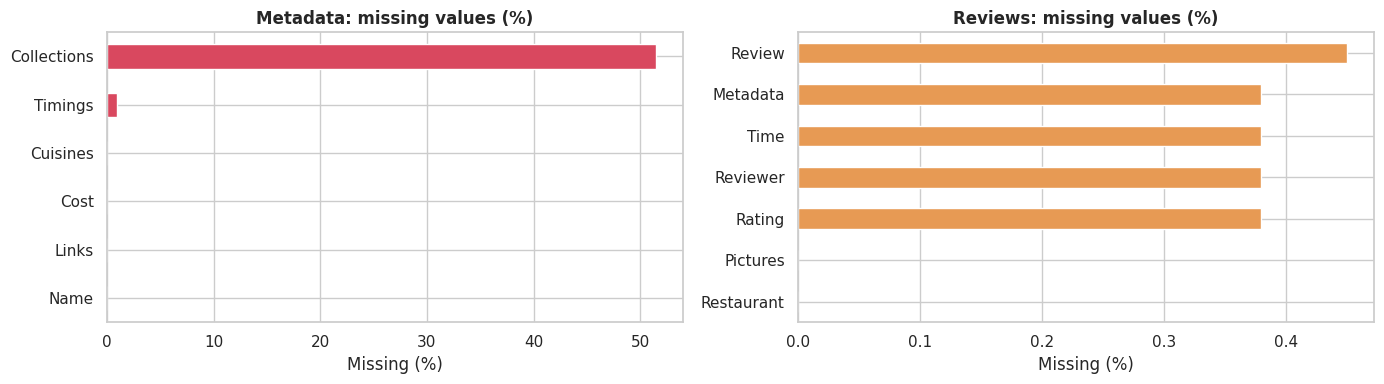

In [19]:
# Visualise missingness by source table
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
metadata_raw.isna().mean().mul(100).sort_values().plot(kind='barh', ax=axes[0], color='#D9485F')
axes[0].set_title('Metadata: missing values (%)')
axes[0].set_xlabel('Missing (%)')
reviews_raw.isna().mean().mul(100).sort_values().plot(kind='barh', ax=axes[1], color='#E79A54')
axes[1].set_title('Reviews: missing values (%)')
axes[1].set_xlabel('Missing (%)')
plt.tight_layout()
plt.show()

The metadata file contains 105 restaurant records and six columns. The review file contains 10,000 review records and seven columns. The restaurant names provide a direct join key; all review restaurant names are represented in the metadata file. The review data contain 36 exact duplicate rows. Missingness is concentrated in collection tags and a few review fields. Ratings are stored as text and include a non-numeric value (`Like`), so they must be converted carefully. The metadata file has no duplicate restaurant names. The analysis represents a Hyderabad restaurant sample, as shown by the supplied restaurant URLs and the accompanying project brief.

## 2. Understanding Your Variables

In [20]:
# Column names in both source datasets
print('Metadata columns:', metadata_raw.columns.tolist())
print('Review columns:', reviews_raw.columns.tolist())

Metadata columns: ['Name', 'Links', 'Cost', 'Collections', 'Cuisines', 'Timings']
Review columns: ['Restaurant', 'Reviewer', 'Review', 'Rating', 'Metadata', 'Time', 'Pictures']


In [21]:
# Descriptive statistics for numeric and categorical fields
print('Metadata summary')
display(metadata_raw.describe(include='all').T)
print('Review summary')
display(reviews_raw.describe(include='all').T)

Metadata summary


,count,unique,top,freq
Name,105,105,Beyond Flavours,1
Links,105,105,https://www.zomato.com/hyderabad/beyond-flavou...,1
Cost,105,29,500,13
Collections,51,42,Food Hygiene Rated Restaurants in Hyderabad,4
Cuisines,105,92,"North Indian, Chinese",4
Timings,104,77,11 AM to 11 PM,6


Review summary


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Restaurant,10000,100,Beyond Flavours,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Reviewer,9962,7446,Parijat Ray,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Review,9955,9364,good,237,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rating,9962,10,5,3832,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Metadata,9962,2477,1 Review,919,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Time,9962,9782,7/29/2018 20:34,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pictures,10000.0,NaN,NaN,NaN,0.7486,2.570381,0.0,0.0,0.0,0.0,64.0


### Check Unique Values for each variable

In [22]:
# Unique values and examples help identify free-text fields and inconsistent categories
unique_summary = pd.DataFrame({
    'Column': metadata_raw.columns.tolist() + reviews_raw.columns.tolist(),
    'Unique_Values': [metadata_raw[c].nunique(dropna=True) for c in metadata_raw.columns] +
                     [reviews_raw[c].nunique(dropna=True) for c in reviews_raw.columns]
})
display(unique_summary)
print('Raw rating values:', sorted(reviews_raw['Rating'].dropna().astype(str).unique())[:20])

,Column,Unique_Values
0,Name,105
1,Links,105
2,Cost,29
3,Collections,42
4,Cuisines,92
5,Timings,77
6,Restaurant,100
7,Reviewer,7446
8,Review,9364
9,Rating,10


Raw rating values: ['1', '1.5', '2', '2.5', '3', '3.5', '4', '4.5', '5', 'Like']


## 3. Data Wrangling

In [23]:
# 1) Create working copies and remove exact duplicate rows from reviews.
#    Keep the original *_raw DataFrames unchanged for traceability.
metadata = metadata_raw.drop_duplicates(subset=['Name']).copy()
reviews = reviews_raw.drop_duplicates().copy()

In [24]:
# 2) Parse metadata fields.
metadata['Cost_INR'] = pd.to_numeric(
    metadata['Cost'].astype(str).str.replace(',', '', regex=False), errors='coerce'
)
metadata['Cuisine_List'] = metadata['Cuisines'].fillna('').apply(
    lambda value: [item.strip() for item in str(value).split(',') if item.strip()]
)
metadata['Collection_List'] = metadata['Collections'].fillna('').apply(
    lambda value: [item.strip() for item in str(value).split(',') if item.strip()]
)
metadata['Cuisine_Count'] = metadata['Cuisine_List'].apply(len)
metadata['Collection_Count'] = metadata['Collection_List'].apply(len)


In [25]:
# 3) Convert review-level fields. Invalid ratings (including the text 'Like')
#    become missing rather than being assigned an invented numeric score.
reviews['Rating_num'] = pd.to_numeric(reviews['Rating'], errors='coerce')
reviews['Pictures'] = pd.to_numeric(reviews['Pictures'], errors='coerce').fillna(0)
reviews['Time_parsed'] = pd.to_datetime(reviews['Time'], errors='coerce')
reviews['Review_word_count'] = reviews['Review'].fillna('').astype(str).str.split().str.len()


In [26]:
# Reviewer metadata has patterns such as "3 Reviews, 12 Followers".
reviews['Reviewer_Reviews'] = pd.to_numeric(
    reviews['Metadata'].fillna('').str.extract(r'(\d+)\s+Reviews?', expand=False), errors='coerce'
)
reviews['Reviewer_Followers'] = pd.to_numeric(
    reviews['Metadata'].fillna('').str.extract(r'(\d+)\s+Followers?', expand=False), errors='coerce'
)


In [27]:
# 4) Review polarity. TextBlob is preferred; a transparent lexicon fallback is
#    used if TextBlob is unavailable in the execution environment.
POSITIVE_WORDS = {'good','great','excellent','amazing','awesome','delicious','tasty','friendly','quick','fresh','love','loved','best','wonderful','perfect','fantastic','superb','nice','clean','prompt','beautiful'}
NEGATIVE_WORDS = {'bad','poor','worst','awful','terrible','rude','slow','cold','stale','bland','disappointing','waste','overpriced','dirty','unhygienic','late','tasteless',' pathetic'}

def review_polarity(value):
    text = str(value) if pd.notna(value) else ''
    if not text.strip():
        return np.nan
    if TextBlob is not None:
        return float(TextBlob(text).sentiment.polarity)
    tokens = re.findall(r'[a-z]+', text.lower())
    if not tokens:
        return 0.0
    score = sum(word in POSITIVE_WORDS for word in tokens) - sum(word in NEGATIVE_WORDS for word in tokens)
    return float(score / max(len(tokens), 1))

reviews['Sentiment'] = reviews['Review'].apply(review_polarity)

In [28]:
# 5) Merge metadata to reviews. Left join preserves all restaurants, including
#    the five catalogue entries without any matching review row.
merged_df = metadata.merge(
    reviews, left_on='Name', right_on='Restaurant', how='left', validate='one_to_many'
)

In [29]:
# 6) Aggregate review information to one row per restaurant for EDA/modeling.
review_features = reviews.groupby('Restaurant').agg(
    Review_Count=('Restaurant', 'size'),
    Rated_Review_Count=('Rating_num', 'count'),
    Avg_Rating=('Rating_num', 'mean'),
    Median_Rating=('Rating_num', 'median'),
    Rating_Std=('Rating_num', 'std'),
    Positive_Share=('Rating_num', lambda x: (x.dropna() >= 4).mean() if x.notna().any() else np.nan),
    Negative_Share=('Rating_num', lambda x: (x.dropna() <= 2).mean() if x.notna().any() else np.nan),
    Mean_Sentiment=('Sentiment', 'mean'),
    Mean_Pictures=('Pictures', 'mean'),
    Mean_Review_Word_Count=('Review_word_count', 'mean'),
    Mean_Reviewer_Followers=('Reviewer_Followers', 'mean'),
    Mean_Reviewer_Reviews=('Reviewer_Reviews', 'mean'),
    Text_Review_Count=('Review', lambda x: x.notna().sum())
).reset_index()

restaurant_eda = metadata.merge(
    review_features, left_on='Name', right_on='Restaurant', how='left', validate='one_to_one'
)
restaurant_eda['Has_Reviews'] = restaurant_eda['Review_Count'].fillna(0).gt(0).astype(int)


In [30]:
# 7) Create a reviewer-level view for reviewer activity analysis.
reviewer_summary = reviews.dropna(subset=['Reviewer']).groupby('Reviewer').agg(
    Rows_In_Sample=('Reviewer', 'size'),
    Reported_Reviews=('Reviewer_Reviews', 'mean'),
    Reported_Followers=('Reviewer_Followers', 'mean')
).reset_index()

print('Clean metadata rows:', len(metadata))
print('Raw review rows:', len(reviews_raw))
print('Exact duplicate review rows removed:', len(reviews_raw) - len(reviews))
print('Unique review rows retained:', len(reviews))
print('Merged rows:', len(merged_df))
print('Restaurants with reviews:', int(restaurant_eda['Has_Reviews'].sum()))
print('Restaurants without reviews:', int((restaurant_eda['Has_Reviews'] == 0).sum()))
print('Valid numeric ratings:', int(reviews['Rating_num'].notna().sum()))

display(restaurant_eda[['Name','Cost_INR','Cuisine_Count','Collection_Count','Review_Count','Avg_Rating','Mean_Sentiment','Has_Reviews']].head())


Clean metadata rows: 105
Raw review rows: 10000
Exact duplicate review rows removed: 36
Unique review rows retained: 9964
Merged rows: 9969
Restaurants with reviews: 100
Restaurants without reviews: 5
Valid numeric ratings: 9961


,Name,Cost_INR,Cuisine_Count,Collection_Count,Review_Count,Avg_Rating,Mean_Sentiment,Has_Reviews
0,Beyond Flavours,800,6,6,100.0,4.28,0.419231,1
1,Paradise,800,3,1,100.0,4.70,0.480494,1
2,Flechazo,1300,4,2,100.0,4.66,0.531244,1
3,Shah Ghouse Hotel & Restaurant,800,5,1,100.0,3.21,0.134391,1
4,Over The Moon Brew Company,1200,5,5,100.0,4.34,0.393337,1


In [31]:
# Export the joined review-level table and restaurant-level analytical view.
merged_df.to_csv(OUTPUT_DIR / 'zomato_merged_cleaned_reviews.csv', index=False)
restaurant_eda.to_csv(OUTPUT_DIR / 'zomato_restaurant_level_features.csv', index=False)
print('Saved merged and restaurant-level datasets to:', OUTPUT_DIR.resolve())

Saved merged and restaurant-level datasets to: /content/outputs


The two datasets were joined with a left one-to-many merge using metadata `Name` and review `Restaurant`. Exact duplicate review rows were removed first (36 rows), leaving 9,964 unique review records. The left join produced 9,969 merged rows: 9,964 review rows plus one retained catalogue-only row for each of the five restaurants without reviews. Costs were parsed as numeric INR values; ratings were converted to numeric and non-numeric entries became missing; cuisine and collection strings were split into lists and counted; review timestamps, picture counts, word counts, and reviewer-reported review/follower counts were parsed. Review sentiment polarity was computed from the original review text. Restaurant-level aggregates were then created so that clustering uses 100 reviewed restaurants as 100 observations, not 9,964 review rows. The five restaurants without reviews remain visible in the catalogue and are flagged as unclassified due to insufficient review evidence.

## 4. Data Visualisation, Storytelling & Experimenting with Charts

The EDA follows the UBM structure: Univariate, Bivariate, and Multivariate analysis. Each chart is followed by its rationale, observed pattern, and possible business use. Descriptions should be interpreted as associations in this historical sample, not causal conclusions.

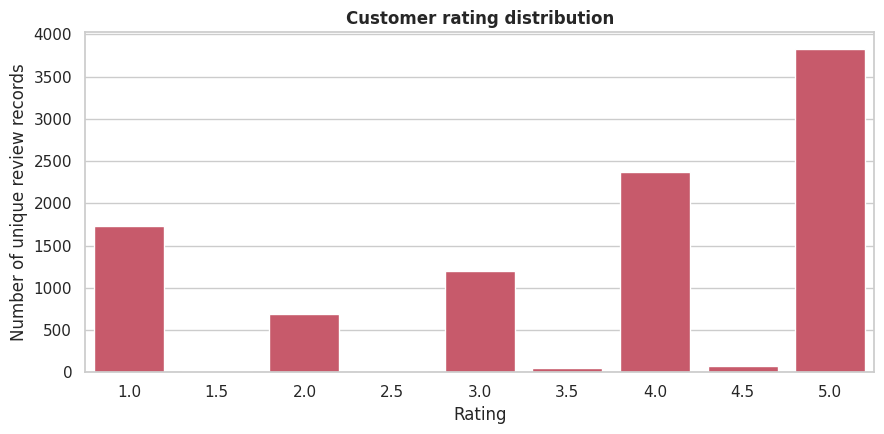

In [32]:
# Chart 1: Distribution of numeric customer ratings (Univariate)
fig, ax = plt.subplots(figsize=(9, 4.5))
rating_order = sorted(reviews['Rating_num'].dropna().unique())
sns.countplot(data=reviews.dropna(subset=['Rating_num']), x='Rating_num', order=rating_order,
              color='#D9485F', ax=ax)
ax.set_title('Customer rating distribution')
ax.set_xlabel('Rating')
ax.set_ylabel('Number of unique review records')
plt.tight_layout(); plt.show()

The count plot is appropriate because the rating is a discrete ordinal variable. It makes the concentration of low and high ratings easy to compare without assuming a continuous normal distribution.

The distribution is polarised toward the endpoints: 5-star reviews are the largest group (3,832), followed by 4-star reviews (2,373) and 1-star reviews (1,735). This indicates strong positive experiences alongside a substantial dissatisfied group; the mean rating alone would hide this spread.

The large 5-star group supports promotion of consistently strong experiences. The 1-star group is also material and should be investigated for recurring food, service, value, or hygiene issues. A business should monitor both high-rating drivers and negative-review themes rather than optimise only the average.

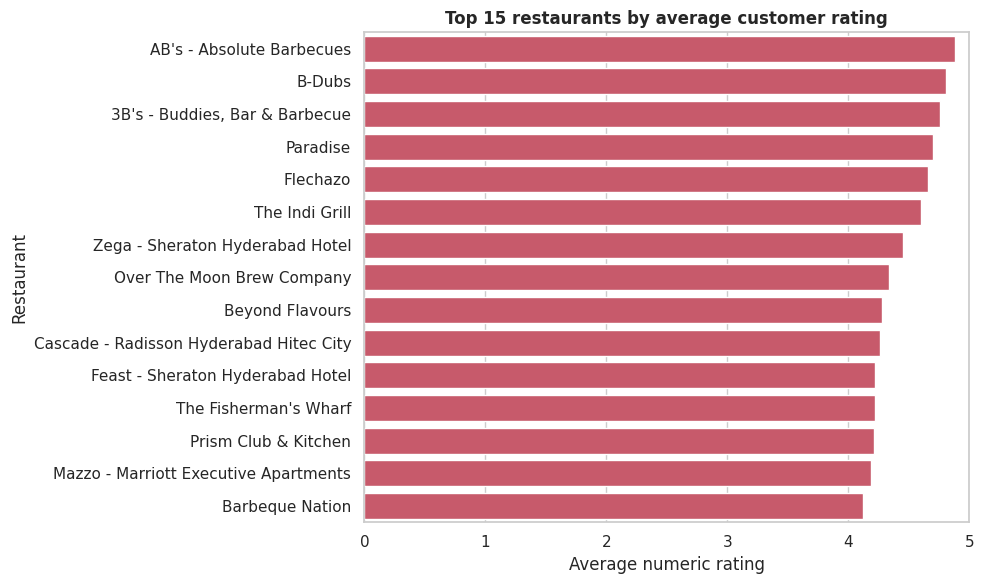

In [33]:
# Chart 2: Highest average restaurant ratings (Bivariate: restaurant vs rating)
plot_df = restaurant_eda.dropna(subset=['Avg_Rating']).sort_values('Avg_Rating', ascending=False).head(15)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=plot_df, y='Name', x='Avg_Rating', color='#D9485F', ax=ax)
ax.set_title('Top 15 restaurants by average customer rating')
ax.set_xlabel('Average numeric rating')
ax.set_ylabel('Restaurant')
ax.set_xlim(0, 5)
plt.tight_layout(); plt.show()

A horizontal bar chart supports ranking many long restaurant names while keeping the rating scale consistent from 0 to 5.

The highest mean ratings are recorded for AB's - Absolute Barbecues (4.88), B-Dubs (4.81), and 3B's - Buddies, Bar & Barbecue (4.76). The sample also includes several restaurants above 4.2, indicating that high customer satisfaction is not limited to one restaurant type.

These restaurants are candidates for studying repeatable service and menu practices. The ranking is based on the supplied review sample and should be accompanied by review counts; it is not a current public ranking or a causal estimate of quality.

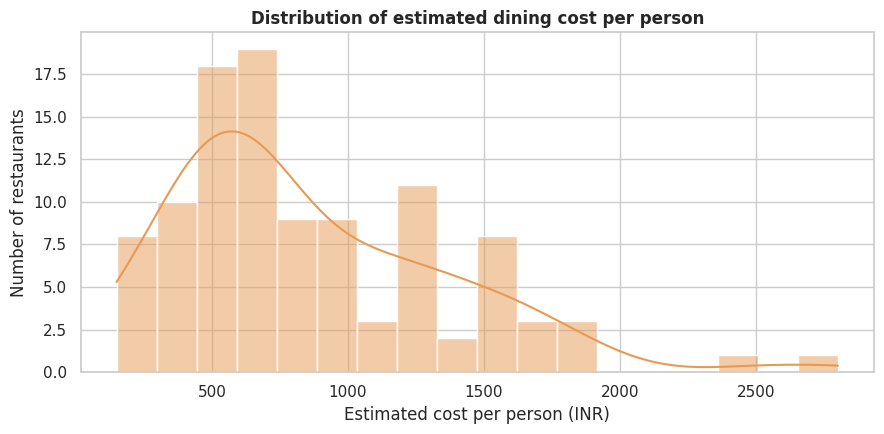

In [34]:
# Chart 3: Estimated dining cost per person (Univariate)
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(data=restaurant_eda, x='Cost_INR', bins=18, kde=True, color='#E79A54', ax=ax)
ax.set_title('Distribution of estimated dining cost per person')
ax.set_xlabel('Estimated cost per person (INR)')
ax.set_ylabel('Number of restaurants')
plt.tight_layout(); plt.show()

A histogram with a density curve reveals the range, concentration, and skew of a numeric cost variable.

The estimated cost ranges from INR 150 to INR 2,800 per person, with a median of INR 700 and a mean of approximately INR 861. The distribution is right-skewed: most restaurants are in lower and middle price bands, while a smaller premium group extends the upper tail.

The price distribution can support budget-aware discovery and help operators benchmark their positioning. Premium values should not be removed automatically as outliers because they may represent genuine high-end restaurants.

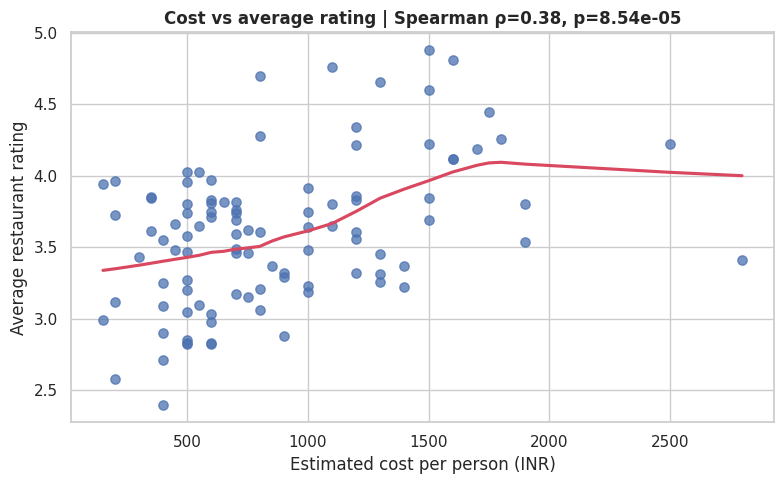

In [35]:
# Chart 4: Estimated cost vs average restaurant rating (Bivariate)
plot_df = restaurant_eda.dropna(subset=['Cost_INR','Avg_Rating'])
rho, p_value = spearmanr(plot_df['Cost_INR'], plot_df['Avg_Rating'])
fig, ax = plt.subplots(figsize=(8, 5))
sns.regplot(data=plot_df, x='Cost_INR', y='Avg_Rating', lowess=True,
            scatter_kws={'alpha':0.75, 's':45}, line_kws={'color':'#D9485F'}, ax=ax)
ax.set_title(f'Cost vs average rating | Spearman ρ={rho:.2f}, p={p_value:.3g}')
ax.set_xlabel('Estimated cost per person (INR)')
ax.set_ylabel('Average restaurant rating')
plt.tight_layout(); plt.show()

A scatter plot shows the distribution of restaurant-level observations; a smooth trend line helps reveal the direction of the relationship. Spearman correlation is added because the relationship need not be linear.

The association is positive and moderate (Spearman ρ ≈ 0.383, p ≈ 8.5 × 10⁻⁵). Higher-cost restaurants tend to have higher average ratings in this sample, but the points are widely dispersed, so cost does not determine rating.

The result supports price-versus-experience benchmarking. Operators charging premium prices should ensure that service and food quality justify the premium. Customers can use the relationship as a broad guide, not as a rule that expensive restaurants are always better.

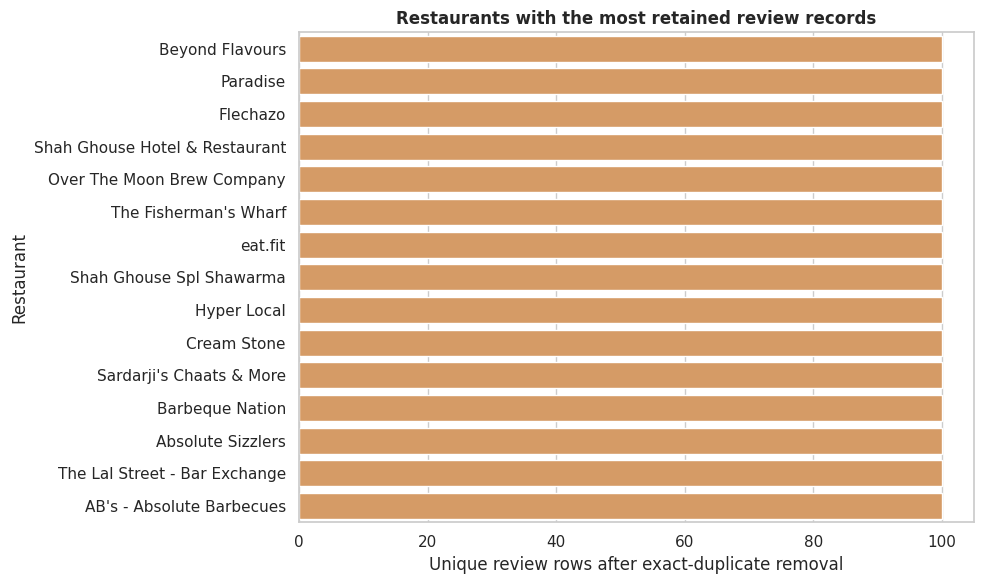

In [36]:
# Chart 5: Restaurants with the largest number of retained review records
plot_df = restaurant_eda.dropna(subset=['Review_Count']).sort_values('Review_Count', ascending=False).head(15)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=plot_df, y='Name', x='Review_Count', color='#E79A54', ax=ax)
ax.set_title('Restaurants with the most retained review records')
ax.set_xlabel('Unique review rows after exact-duplicate removal')
ax.set_ylabel('Restaurant')
plt.tight_layout(); plt.show()

A ranked bar chart is suitable for comparing the number of observations available for each restaurant after duplicate removal.

The source was sampled at roughly 100 reviews per reviewed restaurant. After exact duplicates are removed, the retained review counts differ slightly, so a restaurant's average should be interpreted alongside its actual rating count rather than assuming identical sample sizes.

This chart is mainly a data-quality and coverage diagnostic. It helps identify restaurants with relatively fewer observations, where the average rating may be less stable. Collecting more reviews would improve confidence in those restaurant-level estimates.

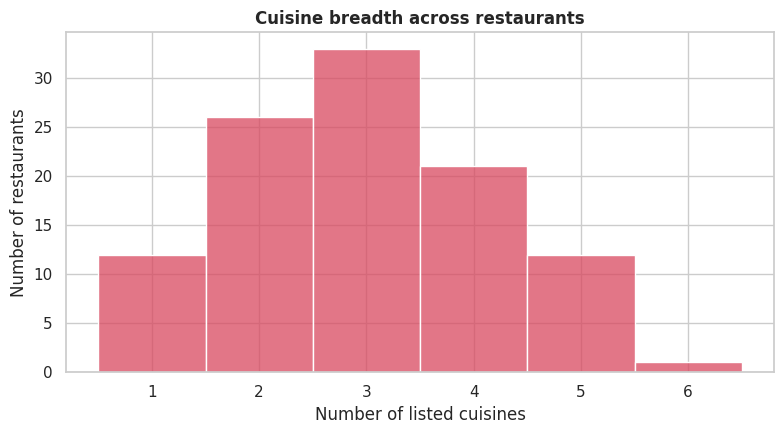

In [37]:
# Chart 6: Number of cuisines offered per restaurant (Univariate)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(data=restaurant_eda, x='Cuisine_Count', discrete=True, color='#D9485F', ax=ax)
ax.set_title('Cuisine breadth across restaurants')
ax.set_xlabel('Number of listed cuisines')
ax.set_ylabel('Number of restaurants')
plt.tight_layout(); plt.show()

A discrete histogram is appropriate for a count variable and reveals whether restaurants specialise in one cuisine or offer broader menus.

Most restaurants list multiple cuisines. The mean cuisine count is about 3, and a smaller group lists a broad range of cuisine types. Cuisine breadth alone does not guarantee higher ratings; that relationship is tested separately.

Menu breadth can help position a restaurant for groups with different preferences, while a focused menu may support operational simplicity. Operators should avoid treating a larger cuisine count as a quality proxy.

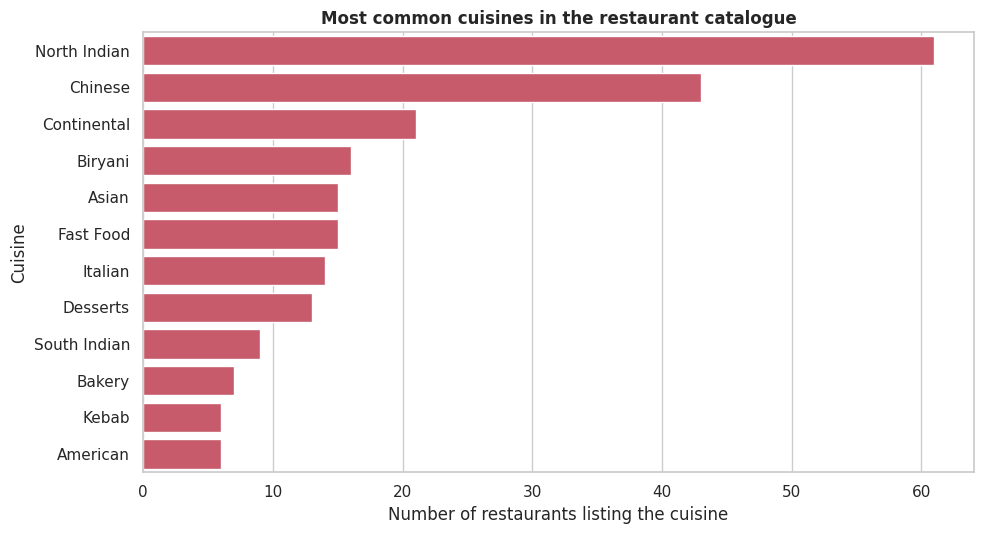

In [38]:
# Chart 7: Most frequently listed cuisines across the restaurant catalogue
cuisine_counts = Counter(cuisine for cuisines in restaurant_eda['Cuisine_List'] for cuisine in cuisines)
cuisine_plot = pd.DataFrame(cuisine_counts.most_common(12), columns=['Cuisine','Restaurant_Count'])
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.barplot(data=cuisine_plot, y='Cuisine', x='Restaurant_Count', color='#D9485F', ax=ax)
ax.set_title('Most common cuisines in the restaurant catalogue')
ax.set_xlabel('Number of restaurants listing the cuisine')
ax.set_ylabel('Cuisine')
plt.tight_layout(); plt.show()

The horizontal bar chart ranks the most common cuisine tags and is more readable than a pie chart when categories have different frequencies.

North Indian is the most frequently listed cuisine (61 restaurants), followed by Chinese (43) and Continental (21). Biryani, Asian, Fast Food, and Italian also appear frequently. Restaurants may list several cuisines, so the counts overlap and do not sum to 105.

The result can guide category navigation, cuisine-specific promotions, and assortment analysis. The overlap must be remembered: these are restaurant tag counts, not mutually exclusive market shares or customer-demand volumes.

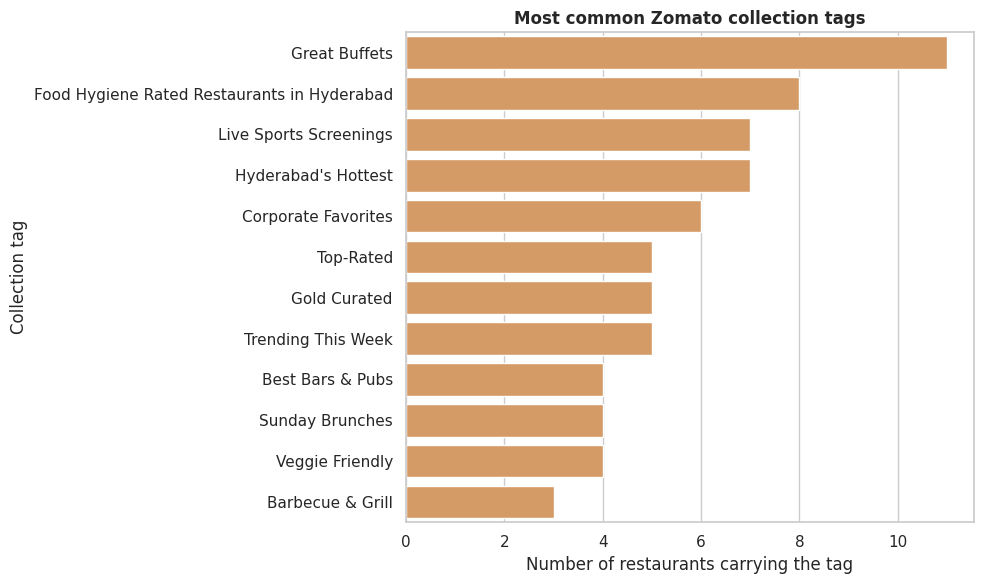

In [39]:
# Chart 8: Most frequent Zomato collection tags
collection_counts = Counter(tag for tags in restaurant_eda['Collection_List'] for tag in tags)
collection_plot = pd.DataFrame(collection_counts.most_common(12), columns=['Collection','Restaurant_Count'])
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=collection_plot, y='Collection', x='Restaurant_Count', color='#E79A54', ax=ax)
ax.set_title('Most common Zomato collection tags')
ax.set_xlabel('Number of restaurants carrying the tag')
ax.set_ylabel('Collection tag')
plt.tight_layout(); plt.show()

A ranked bar chart makes the most common editorial tags visible and supports category-level interpretation.

A subset of collection tags is used repeatedly, while many tags appear only for a few restaurants. These tags provide editorial context, not verified operational attributes; they should be treated as source labels rather than ground-truth categories.

Collection tags can improve restaurant discovery and campaign targeting. The business should validate the meaning and currency of each tag before using it in operational decisions.

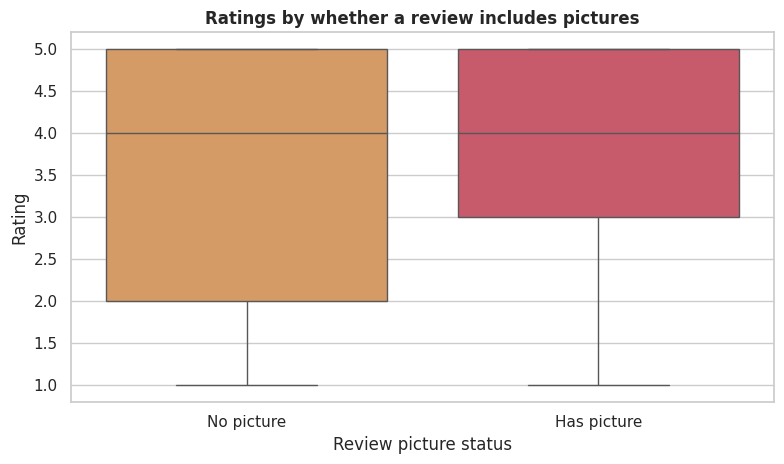

In [40]:
# Chart 9: Rating distribution for reviews with and without pictures
picture_reviews = reviews.dropna(subset=['Rating_num']).copy()
picture_reviews['Picture_Status'] = np.where(picture_reviews['Pictures'] > 0, 'Has picture', 'No picture')
fig, ax = plt.subplots(figsize=(8, 4.8))
sns.boxplot(data=picture_reviews, x='Picture_Status', y='Rating_num',
            order=['No picture','Has picture'], palette=['#E79A54','#D9485F'], ax=ax)
ax.set_title('Ratings by whether a review includes pictures')
ax.set_xlabel('Review picture status')
ax.set_ylabel('Rating')
plt.tight_layout(); plt.show()

A box plot compares the median, interquartile range, and spread of ordinal ratings across two independent groups.

Both groups have a median rating of 4. Reviews with pictures have a higher mean rating (approximately 3.86) than reviews without pictures (approximately 3.54). The difference is statistically significant under a Mann–Whitney U test (p ≈ 0.0026), although the median is unchanged.

Picture-bearing reviews may be more likely to accompany engaging experiences, but the association is not causal. Zomato should not interpret pictures as a quality signal without further controls for restaurant, reviewer, and review-selection effects.

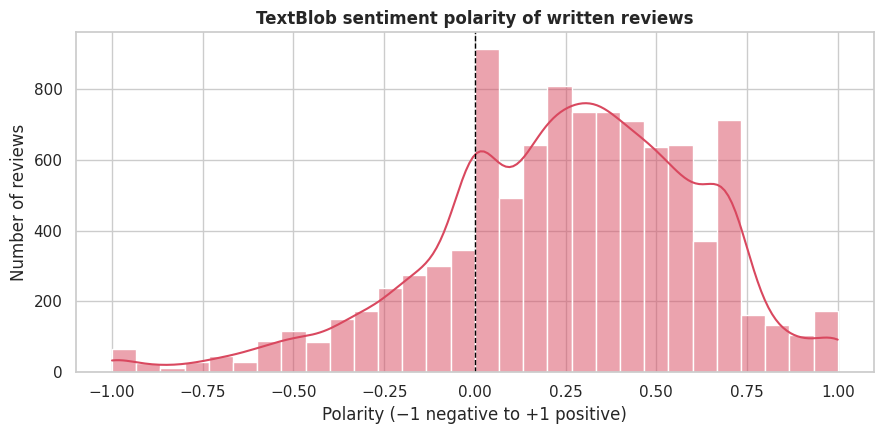

In [41]:
# Chart 10: Review sentiment polarity (Univariate)
sentiment_plot = reviews['Sentiment'].dropna()
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(sentiment_plot, bins=30, kde=True, color='#D9485F', ax=ax)
ax.axvline(0, color='black', linestyle='--', linewidth=1)
ax.set_title('TextBlob sentiment polarity of written reviews')
ax.set_xlabel('Polarity (−1 negative to +1 positive)')
ax.set_ylabel('Number of reviews')
plt.tight_layout(); plt.show()

A histogram is appropriate for the continuous sentiment polarity score and shows whether review language is concentrated around positive or negative wording.

The mean polarity is approximately 0.25, indicating a positive skew in the review text overall. The distribution still includes negative-polarity reviews, so the positive average should not conceal specific dissatisfaction themes.

Sentiment monitoring can help teams identify shifts in customer language before average ratings move. Automated polarity is approximate; important decisions should be validated with manual review or a domain-specific sentiment model.

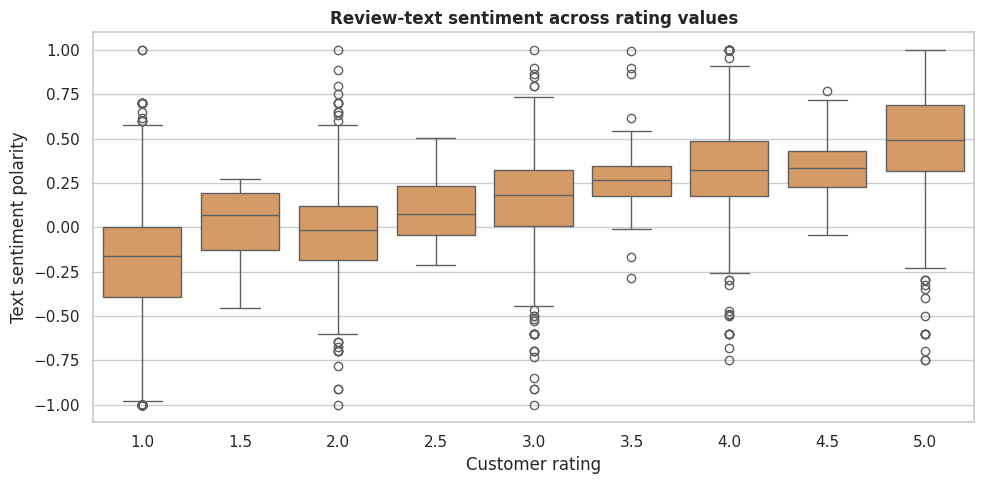

In [42]:
# Chart 11: Sentiment polarity across numeric rating values
sentiment_by_rating = reviews.dropna(subset=['Rating_num','Sentiment']).copy()
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=sentiment_by_rating, x='Rating_num', y='Sentiment',
            order=sorted(sentiment_by_rating['Rating_num'].unique()), color='#E79A54', ax=ax)
ax.set_title('Review-text sentiment across rating values')
ax.set_xlabel('Customer rating')
ax.set_ylabel('Text sentiment polarity')
plt.tight_layout(); plt.show()

A grouped box plot compares the sentiment distribution for each rating value and checks whether written language broadly agrees with the numeric score.

Average sentiment generally rises with the rating: 1-star reviews have negative mean polarity (about −0.20), while 5-star reviews have strongly positive mean polarity (about 0.48). Some overlap remains because written language can be mixed, sarcastic, or neutral even when the numeric rating is clear.

Agreement between text and ratings supports using both signals in restaurant profiles. Cases with a high rating but negative text (or the reverse) can be prioritised for quality review rather than automatically re-scored.

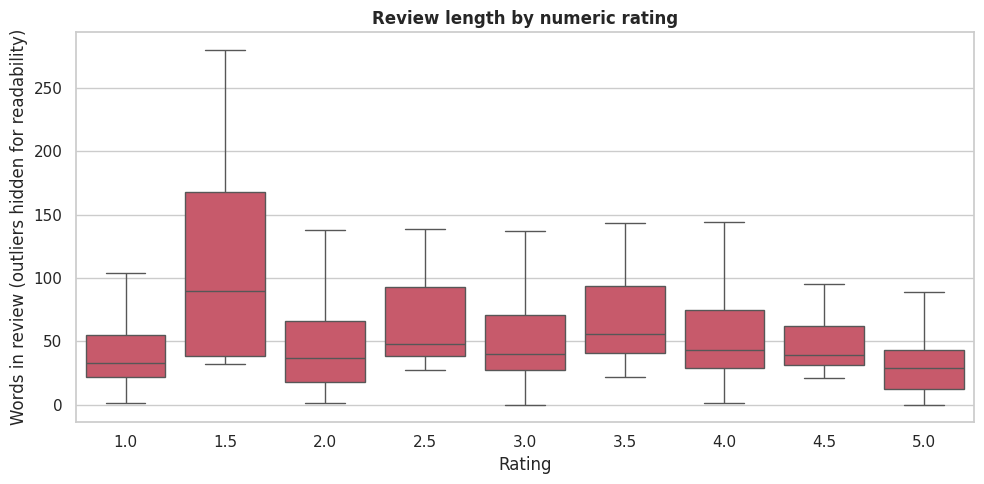

In [43]:
# Chart 12: Review length by rating
length_plot = reviews.dropna(subset=['Rating_num']).copy()
length_plot['Rating_Label'] = length_plot['Rating_num'].astype(str)
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=length_plot, x='Rating_Label', y='Review_word_count',
            order=[str(x) for x in sorted(length_plot['Rating_num'].unique())],
            showfliers=False, color='#D9485F', ax=ax)
ax.set_title('Review length by numeric rating')
ax.set_xlabel('Rating')
ax.set_ylabel('Words in review (outliers hidden for readability)')
plt.tight_layout(); plt.show()

A box plot is suitable for comparing the skewed distribution of review lengths across rating categories; hiding extreme fliers improves readability without removing them from the analysis.

Review length varies within every rating category. A long review is not necessarily positive or negative; it may simply contain more detail. The plot is therefore better used to understand feedback volume than to infer sentiment from length.

A platform can use unusually detailed reviews for qualitative analysis, but review length should not be used as a standalone quality score. Longer reviews may also require more processing time in a text analytics pipeline.

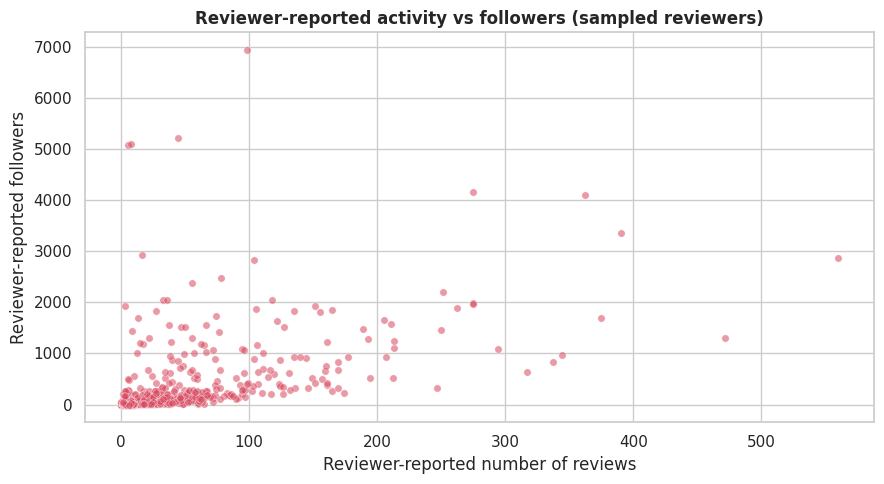

In [44]:
# Chart 13: Reviewer activity and reported audience reach
reviewer_plot = reviewer_summary.dropna(subset=['Reported_Reviews','Reported_Followers']).copy()
reviewer_plot = reviewer_plot.sample(min(1500, len(reviewer_plot)), random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=reviewer_plot, x='Reported_Reviews', y='Reported_Followers',
                alpha=0.55, s=28, color='#D9485F', ax=ax)
ax.set_title('Reviewer-reported activity vs followers (sampled reviewers)')
ax.set_xlabel('Reviewer-reported number of reviews')
ax.set_ylabel('Reviewer-reported followers')
plt.tight_layout(); plt.show()

A scatter plot is appropriate for two numeric reviewer metadata fields and reveals concentration, spread, and potential influential reviewers.

Reviewer metadata is highly dispersed: many sampled reviewers report relatively modest activity and follower counts, while a smaller long-tail group has higher reported reach or review history. The supplied data do not establish that a reviewer is an expert critic; these are profile indicators only.

Reviewers with substantial history or reach may provide useful qualitative context, but their opinions should not automatically receive higher weighting. A fair ranking system should avoid allowing follower count alone to dominate restaurant recommendations.

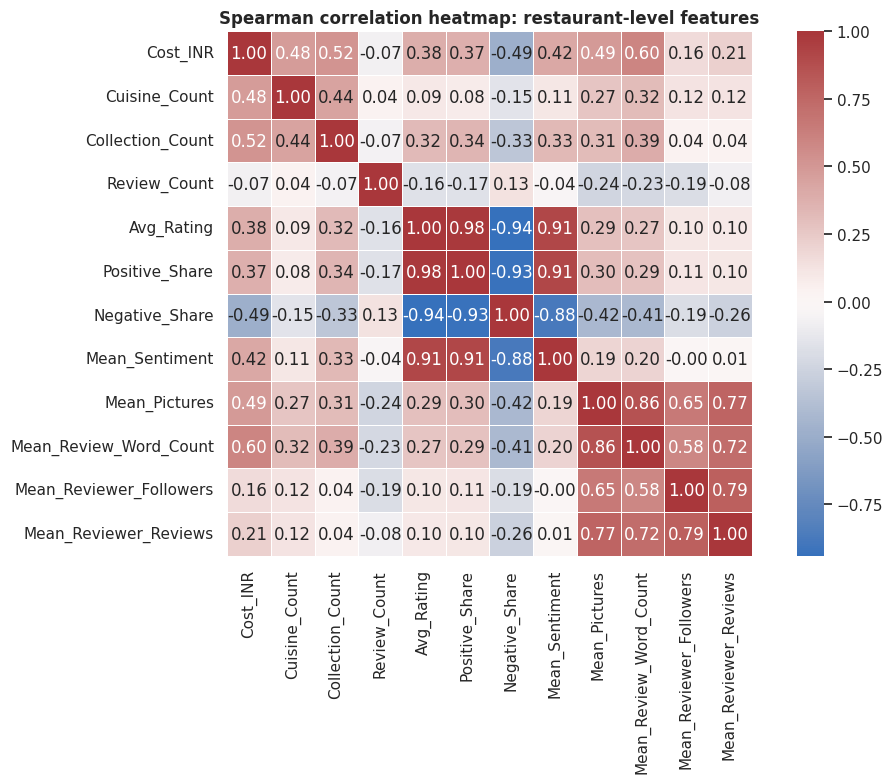

In [45]:
# Chart 14: Correlation heatmap for restaurant-level numeric features
corr_columns = ['Cost_INR','Cuisine_Count','Collection_Count','Review_Count','Avg_Rating',
                'Positive_Share','Negative_Share','Mean_Sentiment','Mean_Pictures',
                'Mean_Review_Word_Count','Mean_Reviewer_Followers','Mean_Reviewer_Reviews']
corr_matrix = restaurant_eda[corr_columns].corr(method='spearman')
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(corr_matrix, cmap='vlag', center=0, annot=True, fmt='.2f',
            square=True, linewidths=.4, ax=ax)
ax.set_title('Spearman correlation heatmap: restaurant-level features')
plt.tight_layout(); plt.show()

The correlation heatmap summarises pairwise monotonic associations across multiple numeric restaurant-level features. Spearman correlation is used because several variables are skewed or ordinal-derived.

The heatmap highlights relationships between average rating, positive/negative review shares, and text sentiment, which are conceptually related but not identical measures. Cost also shows a positive association with average rating in this sample. Correlation does not establish causation and should not be interpreted as independent feature importance.

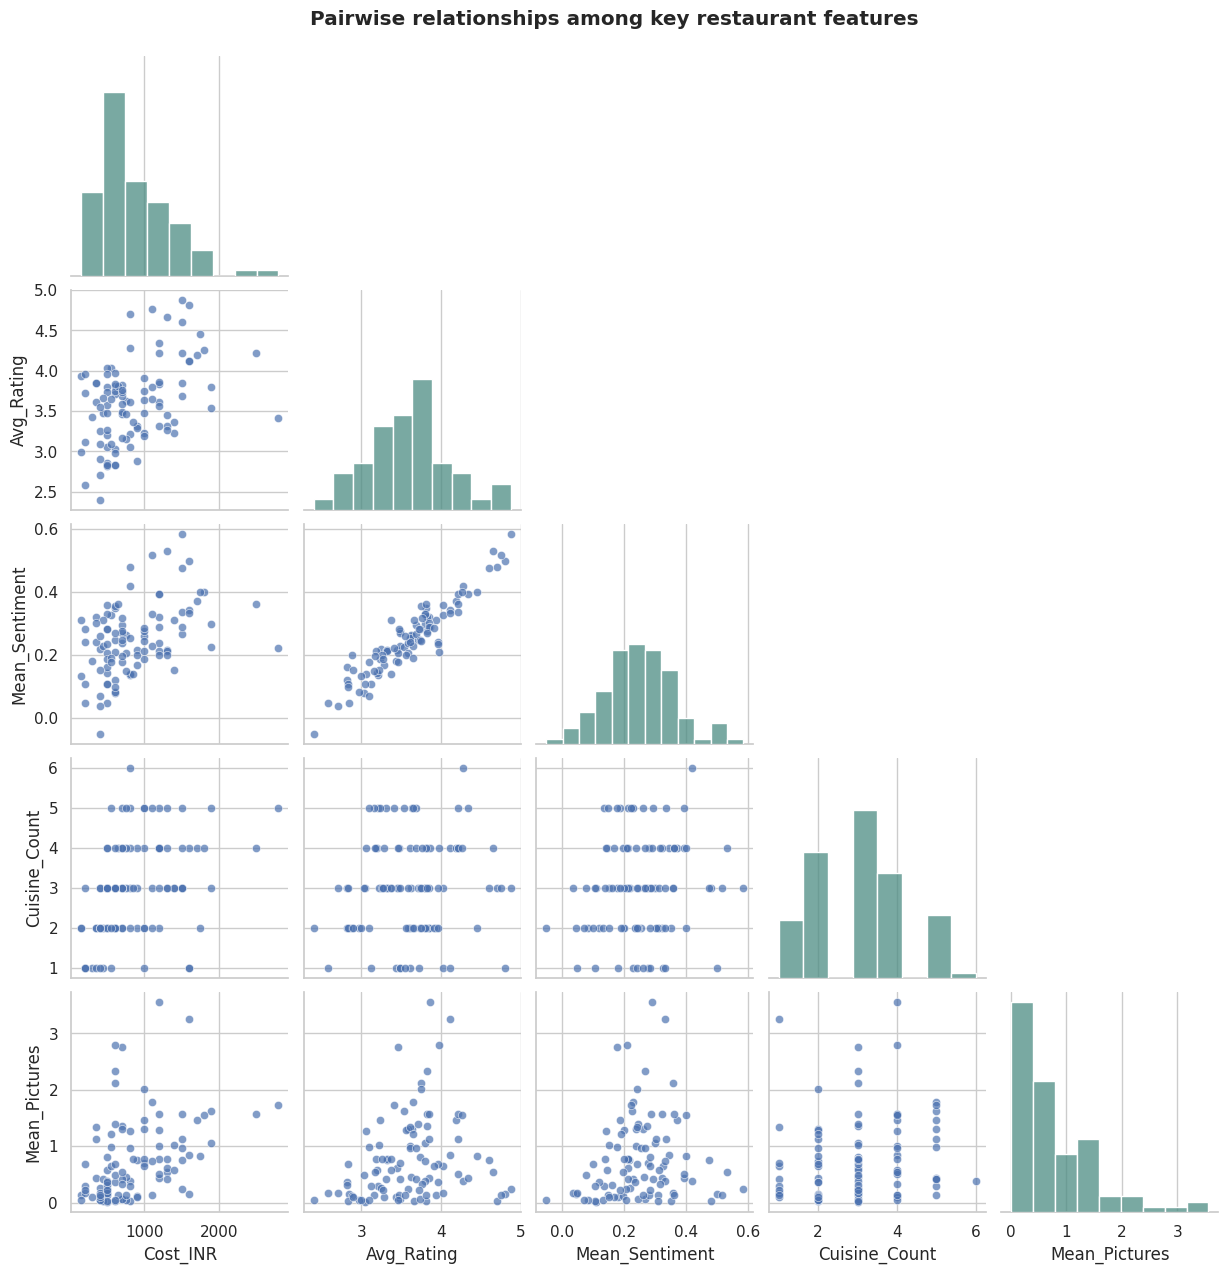

In [46]:
# Chart 15: Pair plot for a compact multivariate feature set
pair_columns = ['Cost_INR','Avg_Rating','Mean_Sentiment','Cuisine_Count','Mean_Pictures']
pair_df = restaurant_eda[pair_columns].dropna().copy()
sns.pairplot(pair_df, corner=True, diag_kind='hist', plot_kws={'alpha':0.7, 's':35}, diag_kws={'color':'#4C8C83'})
plt.suptitle('Pairwise relationships among key restaurant features', y=1.02, fontweight='bold')
plt.show()

The pair plot is an exploratory multivariate diagnostic. It shows each variable's distribution on the diagonal and pairwise relationships off the diagonal, helping identify potential trends and redundant features.

The pair plot is consistent with the earlier charts: cost and rating show a positive but noisy relationship, while sentiment and average rating move in a more aligned direction. The broad scatter across pairs confirms that restaurant segmentation should combine several signals rather than depend on a single metric.

## 5. Hypothesis Testing

Three hypotheses are derived from the visual analysis. The significance level is α = 0.05. Tests are run on the appropriate unit of analysis and results are interpreted as associations, not causal effects.

The tests use restaurant-level observations for cost and cuisine breadth, and review-level observations for picture status. Non-parametric tests are selected to avoid assuming normality for the ordinal rating data.

### Hypothetical Statement 1 — Cost and average rating

**H₀:** There is no monotonic association between estimated dining cost per person and average restaurant rating (Spearman ρ = 0).

**H₁:** Estimated dining cost per person and average restaurant rating have a non-zero monotonic association (Spearman ρ ≠ 0).

The test uses all reviewed restaurants with valid cost and average rating values. The relationship is two-sided because the analysis checks for an association in either direction.

#### 2. Perform an appropriate statistical test

In [47]:
# Spearman rank correlation: cost per person vs average restaurant rating
hyp1_df = restaurant_eda.dropna(subset=['Cost_INR','Avg_Rating'])
hyp1_stat, hyp1_p = spearmanr(hyp1_df['Cost_INR'], hyp1_df['Avg_Rating'])
print(f'n = {len(hyp1_df)} restaurants')
print(f'Spearman rho = {hyp1_stat:.4f}')
print(f'p-value = {hyp1_p:.6g}')
print('Decision:', 'Reject H0' if hyp1_p < 0.05 else 'Fail to reject H0')

n = 100 restaurants
Spearman rho = 0.3826
p-value = 8.54446e-05
Decision: Reject H0


A two-sided Spearman rank-correlation test was used. It tests whether the two ranked variables have a monotonic relationship and does not require the relationship to be linear.

Restaurant-level average ratings and cost are not guaranteed to be normally distributed, and the rating scale originates from ordinal customer ratings. Spearman correlation is therefore more appropriate than relying on Pearson's linearity and normality assumptions. The result is statistically significant (ρ ≈ 0.383, p ≈ 0.000085), so H₀ is rejected. The positive association is moderate, not deterministic.

### Hypothetical Statement 2 — Cuisine breadth and average rating

**H₀:** There is no monotonic association between the number of listed cuisines and average restaurant rating (Spearman ρ = 0).

**H₁:** There is a non-zero monotonic association between cuisine count and average restaurant rating (Spearman ρ ≠ 0).

The analysis uses the same restaurant-level sample as Hypothesis 1. Cuisine count is derived by splitting the comma-separated cuisine field and counting the listed cuisines.

#### 2. Perform an appropriate statistical test

In [48]:
# Spearman rank correlation: cuisine breadth vs average restaurant rating
hyp2_df = restaurant_eda.dropna(subset=['Cuisine_Count','Avg_Rating'])
hyp2_stat, hyp2_p = spearmanr(hyp2_df['Cuisine_Count'], hyp2_df['Avg_Rating'])
print(f'n = {len(hyp2_df)} restaurants')
print(f'Spearman rho = {hyp2_stat:.4f}')
print(f'p-value = {hyp2_p:.6g}')
print('Decision:', 'Reject H0' if hyp2_p < 0.05 else 'Fail to reject H0')

n = 100 restaurants
Spearman rho = 0.0943
p-value = 0.350665
Decision: Fail to reject H0


A two-sided Spearman rank-correlation test was used to check for a monotonic relationship between cuisine count and average rating.

Cuisine count is a discrete count variable and average rating is aggregated from an ordinal scale. Spearman correlation avoids assuming normality or a linear relationship. The result is not statistically significant (ρ ≈ 0.094, p ≈ 0.351), so H₀ is not rejected. The supplied sample does not provide sufficient evidence that listing more cuisines is associated with a higher average rating.

### Hypothetical Statement 3 — Picture-bearing reviews and ratings

**H₀:** The rating distributions are the same for reviews with no pictures and reviews with at least one picture.

**H₁:** The rating distributions differ between reviews with no pictures and reviews with at least one picture.

The test is performed on unique review rows with valid numeric ratings. A review is classified as picture-bearing when its `Pictures` value is greater than zero.

#### 2. Perform an appropriate statistical test

In [49]:
# Mann–Whitney U test: independent rating samples for picture vs no-picture reviews
hyp3_df = reviews.dropna(subset=['Rating_num']).copy()
ratings_no_picture = hyp3_df.loc[hyp3_df['Pictures'] == 0, 'Rating_num']
ratings_with_picture = hyp3_df.loc[hyp3_df['Pictures'] > 0, 'Rating_num']
hyp3_stat, hyp3_p = mannwhitneyu(
    ratings_no_picture, ratings_with_picture, alternative='two-sided'
)
print('No-picture reviews:', len(ratings_no_picture), '| mean:', round(ratings_no_picture.mean(), 3))
print('Picture reviews:', len(ratings_with_picture), '| mean:', round(ratings_with_picture.mean(), 3))
print(f'Mann–Whitney U = {hyp3_stat:.1f}')
print(f'p-value = {hyp3_p:.6g}')
print('Decision:', 'Reject H0' if hyp3_p < 0.05 else 'Fail to reject H0')

No-picture reviews: 7978 | mean: 3.536
Picture reviews: 1983 | mean: 3.863
Mann–Whitney U = 7578718.5
p-value = 0.00259661
Decision: Reject H0


A two-sided Mann–Whitney U test was used to compare the independent rating distributions for reviews with and without pictures.

The outcome is an ordinal rating, and the two groups are independent. The Mann–Whitney U test does not require normally distributed samples. The p-value is approximately 0.0026, so H₀ is rejected at α = 0.05. Reviews with pictures have a higher mean rating in this sample, but both groups have a median of 4. This is an association and does not show that adding a picture causes a higher rating.

## 6. Feature Engineering & Data Pre-processing

### 1. Handling Missing Values

In [50]:
# Inspect missingness in the restaurant-level features used for clustering.
reviewed_restaurants = restaurant_eda.loc[restaurant_eda['Has_Reviews'] == 1].copy()
feature_missingness = reviewed_restaurants[
    ['Cost_INR','Cuisine_Count','Collection_Count','Review_Count','Avg_Rating','Rating_Std',
     'Positive_Share','Negative_Share','Mean_Sentiment','Mean_Pictures',
     'Mean_Review_Word_Count','Mean_Reviewer_Followers','Mean_Reviewer_Reviews']
].isna().sum().sort_values(ascending=False)
display(feature_missingness.to_frame('Missing_Count'))

# Do not impute the five no-review restaurants into the model population.
# They are retained in restaurant_eda and marked as not clusterable from reviews.

,Missing_Count
Cost_INR,0
Cuisine_Count,0
Collection_Count,0
Review_Count,0
Avg_Rating,0
Rating_Std,0
Positive_Share,0
Negative_Share,0
Mean_Sentiment,0
Mean_Pictures,0


The five restaurants without review records are excluded from the review-based clustering matrix and remain explicitly marked as `Not clustered — no review data`. For the 100 reviewed restaurants, occasional missing numeric values (for example, missing reviewer follower metadata or an undefined rating standard deviation) are imputed with the median using `SimpleImputer`. The median is robust to skew and extreme values. Missing review text is kept as an empty string for vectorisation; it is not converted into a fabricated review.

### 2. Handling Outliers

In [51]:
# Identify IQR outliers for key numeric features without deleting valid restaurants.
outlier_columns = ['Cost_INR','Avg_Rating','Mean_Pictures','Mean_Reviewer_Followers']
outlier_rows = []
for column in outlier_columns:
    values = reviewed_restaurants[column].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = int(((values < lower) | (values > upper)).sum())
    outlier_rows.append([column, q1, q3, lower, upper, count])
outlier_report = pd.DataFrame(
    outlier_rows, columns=['Feature','Q1','Q3','Lower_Fence','Upper_Fence','Outlier_Count']
)
display(outlier_report.round(2))

,Feature,Q1,Q3,Lower_Fence,Upper_Fence,Outlier_Count
0,Cost_INR,500.00,1200.00,-550.00,2250.00,2
1,Avg_Rating,3.24,3.85,2.34,4.75,3
2,Mean_Pictures,0.17,1.13,-1.27,2.57,4
3,Mean_Reviewer_Followers,107.95,246.51,-99.90,454.35,4


IQR fences are used to flag potential outliers. No restaurants are deleted and no valid cost values are winsorised: high estimated costs may describe genuine premium establishments, and the sample is small. Standardisation and PCA are applied before distance-based clustering. Outlier flags should be revisited with business context if the model is redeployed on a larger dataset.

In [52]:
# Multi-label encode the ten most frequently listed cuisines.
# Cuisine fields are not mutually exclusive, so one-hot flags are appropriate.
model_df = restaurant_eda.loc[restaurant_eda['Has_Reviews'] == 1].copy().reset_index(drop=True)
cuisine_frequency = Counter(
    cuisine for cuisine_list in model_df['Cuisine_List'] for cuisine in cuisine_list
)
top_cuisines = [cuisine for cuisine, _ in cuisine_frequency.most_common(10)]
cuisine_feature_cols = []
for cuisine in top_cuisines:
    column_name = 'Cuisine_' + re.sub(r'\W+', '_', cuisine).strip('_')
    cuisine_feature_cols.append(column_name)
    model_df[column_name] = model_df['Cuisine_List'].apply(lambda values: int(cuisine in values))

print('Top cuisines used as binary features:', top_cuisines)
print('Restaurant-level modelling rows:', len(model_df))
display(model_df[['Name'] + cuisine_feature_cols].head())

Top cuisines used as binary features: ['North Indian', 'Chinese', 'Continental', 'Biryani', 'Asian', 'Italian', 'Desserts', 'Fast Food', 'South Indian', 'Kebab']
Restaurant-level modelling rows: 100


,Name,Cuisine_North_Indian,Cuisine_Chinese,Cuisine_Continental,Cuisine_Biryani,Cuisine_Asian,Cuisine_Italian,Cuisine_Desserts,Cuisine_Fast_Food,Cuisine_South_Indian,Cuisine_Kebab
0,Beyond Flavours,1,1,1,0,0,0,0,0,1,1
1,Paradise,1,1,0,1,0,0,0,0,0,0
2,Flechazo,1,0,0,0,1,0,1,0,0,0
3,Shah Ghouse Hotel & Restaurant,1,1,0,1,0,0,0,0,0,0
4,Over The Moon Brew Company,1,1,1,0,1,0,0,0,0,0


The ten most frequent cuisine tags are encoded as multi-label binary indicators (one column per cuisine). A restaurant can carry several cuisine labels, so single-label ordinal encoding would introduce a false order and lose information. Collection tags are represented by their count to avoid a very sparse one-hot matrix with many rare labels. Restaurant name, URL, and opening-time text are not used as clustering inputs.

### 4. Textual Data Preprocessing

Text processing is applied to review text while the original `Review` column is retained for auditability. The cleaned text is used for TF-IDF/SVD features at restaurant level.

#### 1. Expand Contraction

In [53]:
# Expand common English contractions before token-level cleaning.
CONTRACTIONS = {
    "can't": "cannot", "won't": "will not", "n't": " not", "i'm": "i am",
    "it's": "it is", "you're": "you are", "we're": "we are", "they're": "they are",
    "i've": "i have", "we've": "we have", "that's": "that is", "there's": "there is",
    "what's": "what is", "couldn't": "could not", "wouldn't": "would not",
    "shouldn't": "should not", "isn't": "is not", "aren't": "are not",
    "wasn't": "was not", "weren't": "were not", "don't": "do not",
    "doesn't": "does not", "didn't": "did not", "haven't": "have not",
    "hasn't": "has not", "hadn't": "had not", "let's": "let us"
}

def expand_contractions(text):
    value = str(text) if pd.notna(text) else ''
    for contraction, expansion in sorted(CONTRACTIONS.items(), key=lambda item: -len(item[0])):
        value = re.sub(re.escape(contraction), expansion, value, flags=re.IGNORECASE)
    return value

reviews['Review_expanded'] = reviews['Review'].apply(expand_contractions)
display(reviews[['Review','Review_expanded']].head(5))

,Review,Review_expanded
0,"The ambience was good, food was quite good . h...","The ambience was good, food was quite good . h..."
1,Ambience is too good for a pleasant evening. S...,Ambience is too good for a pleasant evening. S...
2,A must try.. great food great ambience. Thnx f...,A must try.. great food great ambience. Thnx f...
3,Soumen das and Arun was a great guy. Only beca...,Soumen das and Arun was a great guy. Only beca...
4,Food is good.we ordered Kodi drumsticks and ba...,Food is good.we ordered Kodi drumsticks and ba...


#### 2. Lower Casing

In [54]:
# Lowercase all review text for consistent token matching
reviews['Review_lower'] = reviews['Review_expanded'].str.lower()
display(reviews[['Review_expanded','Review_lower']].head(5))

,Review_expanded,Review_lower
0,"The ambience was good, food was quite good . h...","the ambience was good, food was quite good . h..."
1,Ambience is too good for a pleasant evening. S...,ambience is too good for a pleasant evening. s...
2,A must try.. great food great ambience. Thnx f...,a must try.. great food great ambience. thnx f...
3,Soumen das and Arun was a great guy. Only beca...,soumen das and arun was a great guy. only beca...
4,Food is good.we ordered Kodi drumsticks and ba...,food is good.we ordered kodi drumsticks and ba...


#### 3. Removing Punctuations

In [55]:
# Replace punctuation and symbols with spaces; retain alphabetic tokens.
reviews['Review_no_punctuation'] = reviews['Review_lower'].str.replace(r'[^a-z\s]', ' ', regex=True)
display(reviews[['Review_lower','Review_no_punctuation']].head(5))

,Review_lower,Review_no_punctuation
0,"the ambience was good, food was quite good . h...",the ambience was good food was quite good h...
1,ambience is too good for a pleasant evening. s...,ambience is too good for a pleasant evening s...
2,a must try.. great food great ambience. thnx f...,a must try great food great ambience thnx f...
3,soumen das and arun was a great guy. only beca...,soumen das and arun was a great guy only beca...
4,food is good.we ordered kodi drumsticks and ba...,food is good we ordered kodi drumsticks and ba...


#### 4. Removing URLs & Removing words and digits contain digits

In [56]:
# Remove URLs and alphanumeric tokens that contain digits.
reviews['Review_no_urls_digits'] = reviews['Review_lower'].apply(
    lambda text: re.sub(r'\b\w*\d\w*\b', ' ', re.sub(r'https?://\S+|www\.\S+', ' ', text))
)
reviews['Review_no_urls_digits'] = reviews['Review_no_urls_digits'].str.replace(r'[^a-z\s]', ' ', regex=True)
display(reviews[['Review_lower','Review_no_urls_digits']].head(5))

,Review_lower,Review_no_urls_digits
0,"the ambience was good, food was quite good . h...",the ambience was good food was quite good h...
1,ambience is too good for a pleasant evening. s...,ambience is too good for a pleasant evening s...
2,a must try.. great food great ambience. thnx f...,a must try great food great ambience thnx f...
3,soumen das and arun was a great guy. only beca...,soumen das and arun was a great guy only beca...
4,food is good.we ordered kodi drumsticks and ba...,food is good we ordered kodi drumsticks and ba...


#### 5. Removing Stopwords & Removing White Spaces

In [57]:
# Remove common English stop words using scikit-learn's built-in list.
stop_words = set(ENGLISH_STOP_WORDS)
def remove_stopwords(text):
    return ' '.join(token for token in str(text).split() if token not in stop_words and len(token) > 2)
reviews['Review_no_stopwords'] = reviews['Review_no_urls_digits'].apply(remove_stopwords)
display(reviews[['Review_no_urls_digits','Review_no_stopwords']].head(5))

,Review_no_urls_digits,Review_no_stopwords
0,the ambience was good food was quite good h...,ambience good food quite good saturday lunch c...
1,ambience is too good for a pleasant evening s...,ambience good pleasant evening service prompt ...
2,a must try great food great ambience thnx f...,try great food great ambience thnx service pra...
3,soumen das and arun was a great guy only beca...,soumen das arun great guy behavior sincerety g...
4,food is good we ordered kodi drumsticks and ba...,food good ordered kodi drumsticks basket mutto...


In [58]:
# Normalise repeated whitespace and strip leading/trailing spaces.
reviews['Review_whitespace'] = reviews['Review_no_stopwords'].str.replace(r'\s+', ' ', regex=True).str.strip()
display(reviews[['Review_no_stopwords','Review_whitespace']].head(5))

,Review_no_stopwords,Review_whitespace
0,ambience good food quite good saturday lunch c...,ambience good food quite good saturday lunch c...
1,ambience good pleasant evening service prompt ...,ambience good pleasant evening service prompt ...
2,try great food great ambience thnx service pra...,try great food great ambience thnx service pra...
3,soumen das arun great guy behavior sincerety g...,soumen das arun great guy behavior sincerety g...
4,food good ordered kodi drumsticks basket mutto...,food good ordered kodi drumsticks basket mutto...


#### 6. Rephrase Text

In [59]:
# Do not paraphrase customer reviews: rephrasing could alter sentiment or meaning.
# The semantically faithful, normalised text is retained as the model input.
reviews['Review_rephrased'] = reviews['Review_whitespace']
print('Text normalisation completed without generative paraphrasing.')
display(reviews[['Review','Review_rephrased']].head(5))

Text normalisation completed without generative paraphrasing.


,Review,Review_rephrased
0,"The ambience was good, food was quite good . h...",ambience good food quite good saturday lunch c...
1,Ambience is too good for a pleasant evening. S...,ambience good pleasant evening service prompt ...
2,A must try.. great food great ambience. Thnx f...,try great food great ambience thnx service pra...
3,Soumen das and Arun was a great guy. Only beca...,soumen das arun great guy behavior sincerety g...
4,Food is good.we ordered Kodi drumsticks and ba...,food good ordered kodi drumsticks basket mutto...


#### 7. Tokenization

In [60]:
# Tokenise using a simple alphabetic regular expression; no downloaded corpus is required.
reviews['Review_tokens'] = reviews['Review_rephrased'].apply(lambda text: re.findall(r'[a-z]+', text))
display(reviews[['Review_rephrased','Review_tokens']].head(5))

,Review_rephrased,Review_tokens
0,ambience good food quite good saturday lunch c...,"[ambience, good, food, quite, good, saturday, ..."
1,ambience good pleasant evening service prompt ...,"[ambience, good, pleasant, evening, service, p..."
2,try great food great ambience thnx service pra...,"[try, great, food, great, ambience, thnx, serv..."
3,soumen das arun great guy behavior sincerety g...,"[soumen, das, arun, great, guy, behavior, sinc..."
4,food good ordered kodi drumsticks basket mutto...,"[food, good, ordered, kodi, drumsticks, basket..."


#### 8. Text Normalization

In [61]:
# Porter stemming reduces related word forms to a shared token.
try:
    from nltk.stem import PorterStemmer
    porter = PorterStemmer()
    reviews['Review_stemmed'] = reviews['Review_tokens'].apply(
        lambda tokens: ' '.join(porter.stem(token) for token in tokens)
    )
    stemming_method = 'NLTK Porter stemming'
except ImportError:
    # Fallback keeps the notebook executable when NLTK is not installed.
    reviews['Review_stemmed'] = reviews['Review_tokens'].apply(lambda tokens: ' '.join(tokens))
    stemming_method = 'No stemming fallback (NLTK unavailable)'

print('Text normalisation method:', stemming_method)
display(reviews[['Review_tokens','Review_stemmed']].head(5))
reviews.to_csv(OUTPUT_DIR / 'zomato_review_level_preprocessed.csv', index=False)
print('Saved review-level cleaned text and parsed features.')

Text normalisation method: NLTK Porter stemming


,Review_tokens,Review_stemmed
0,"[ambience, good, food, quite, good, saturday, ...",ambienc good food quit good saturday lunch cos...
1,"[ambience, good, pleasant, evening, service, p...",ambienc good pleasant even servic prompt food ...
2,"[try, great, food, great, ambience, thnx, serv...",tri great food great ambienc thnx servic prade...
3,"[soumen, das, arun, great, guy, behavior, sinc...",soumen da arun great guy behavior sincereti go...
4,"[food, good, ordered, kodi, drumsticks, basket...",food good order kodi drumstick basket mutton b...


Saved review-level cleaned text and parsed features.


Porter stemming is used because it is lightweight and does not require downloading a language corpus. It reduces inflectional variants to common stems, which can reduce vocabulary sparsity in TF-IDF. The original review text is never overwritten. Stemming may reduce linguistic nuance, so the resulting components are used as supporting cluster features rather than as a substitute for reading customer feedback.

#### 9. Part of Speech Tagging

In [62]:
# POS tagging is deliberately not applied. The clustering input uses TF-IDF/SVD
# summaries of review content; POS tags are not required for this bag-of-words
# representation. Omitting a downloaded POS model also keeps the notebook offline-safe.
pos_tagging_applied = False
print('POS tagging applied:', pos_tagging_applied, '- not required for this TF-IDF/SVD workflow.')

POS tagging applied: False - not required for this TF-IDF/SVD workflow.


#### 10. Text Vectorization

In [63]:
# Aggregate cleaned reviews to one document per reviewed restaurant.
restaurant_text = reviews.groupby('Restaurant')['Review_stemmed'].apply(
    lambda series: ' '.join(text for text in series if isinstance(text, str) and text.strip())
).rename('All_Reviews_Clean').reset_index()
model_df = model_df.merge(
    restaurant_text, left_on='Name', right_on='Restaurant', how='left', validate='one_to_one'
)
model_df['All_Reviews_Clean'] = model_df['All_Reviews_Clean'].fillna('')

# TF-IDF captures word and bigram importance; TruncatedSVD compresses the sparse
# text matrix into five dense numeric components suitable for clustering.
text_vectorizer = TfidfVectorizer(
    max_features=300, min_df=2, max_df=0.9,
    ngram_range=(1, 2), sublinear_tf=True
)
text_tfidf = text_vectorizer.fit_transform(model_df['All_Reviews_Clean'])
text_svd = TruncatedSVD(n_components=5, random_state=RANDOM_STATE)
text_components = text_svd.fit_transform(text_tfidf)
text_component_cols = []
for component_index in range(text_components.shape[1]):
    col = f'Text_SVD_{component_index + 1}'
    text_component_cols.append(col)
    model_df[col] = text_components[:, component_index]

print('Restaurant text documents:', len(restaurant_text))
print('TF-IDF matrix shape:', text_tfidf.shape)
print('SVD components:', text_components.shape)
print('Variance explained by five text components:', round(text_svd.explained_variance_ratio_.sum(), 4))

Restaurant text documents: 100
TF-IDF matrix shape: (100, 300)
SVD components: (100, 5)
Variance explained by five text components: 0.3586


TF-IDF with unigram and bigram features is used because it weights terms by their importance within a restaurant's aggregated reviews while reducing the influence of terms common across all restaurants. Truncated SVD reduces the sparse 300-term matrix to five dense latent components. The five components explain approximately 35.9% of the TF-IDF matrix variance in this sample; they retain useful language patterns without feeding hundreds of sparse text columns directly into a distance-based model.

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [64]:
# Construct the final restaurant-level feature matrix.
base_numeric_features = [
    'Cost_INR','Cuisine_Count','Collection_Count','Review_Count','Avg_Rating',
    'Rating_Std','Positive_Share','Negative_Share','Mean_Sentiment','Mean_Pictures',
    'Mean_Review_Word_Count','Mean_Reviewer_Followers','Mean_Reviewer_Reviews'
]
feature_columns = base_numeric_features + cuisine_feature_cols + text_component_cols

X_raw = model_df[feature_columns].apply(pd.to_numeric, errors='coerce')

# Median imputation is fitted on the reviewed restaurant population.
feature_imputer = SimpleImputer(strategy='median')
X_imputed_array = feature_imputer.fit_transform(X_raw)
X_imputed = pd.DataFrame(X_imputed_array, columns=feature_columns, index=model_df.index)

print('Number of restaurants used for clustering:', len(model_df))
print('Number of selected features:', len(feature_columns))
print('Feature matrix shape:', X_imputed.shape)
display(X_imputed.head())

Number of restaurants used for clustering: 100
Number of selected features: 28
Feature matrix shape: (100, 28)


,Cost_INR,Cuisine_Count,Collection_Count,Review_Count,Avg_Rating,Rating_Std,Positive_Share,Negative_Share,Mean_Sentiment,Mean_Pictures,...,Cuisine_Italian,Cuisine_Desserts,Cuisine_Fast_Food,Cuisine_South_Indian,Cuisine_Kebab,Text_SVD_1,Text_SVD_2,Text_SVD_3,Text_SVD_4,Text_SVD_5
0,800.0,6.0,6.0,100.0,4.28,1.239746,0.82,0.12,0.419231,0.39,...,0.0,0.0,0.0,1.0,1.0,0.835310,-0.197648,-0.139415,-0.122497,-0.051535
1,800.0,3.0,1.0,100.0,4.70,0.771984,0.96,0.03,0.480494,0.02,...,0.0,0.0,0.0,0.0,0.0,0.674096,0.111211,-0.222230,-0.072323,-0.324967
2,1300.0,4.0,2.0,100.0,4.66,0.878704,0.91,0.06,0.531244,0.55,...,0.0,1.0,0.0,0.0,0.0,0.783701,-0.280887,-0.082769,-0.246965,-0.057176
3,800.0,5.0,1.0,100.0,3.21,1.603626,0.53,0.35,0.134391,0.30,...,0.0,0.0,0.0,0.0,0.0,0.757720,0.314457,-0.129770,0.054145,-0.211325
4,1200.0,5.0,5.0,100.0,4.34,1.065719,0.87,0.07,0.393337,0.44,...,0.0,0.0,0.0,0.0,0.0,0.775587,-0.363702,-0.061011,0.171208,-0.004192


#### 2. Feature Selection

In [65]:
# Remove only zero-variance features; retain interpretable numeric, cuisine,
# reviewer, sentiment, and text-component features with non-zero variance.
feature_variances = X_imputed.var().sort_values(ascending=False)
selected_features = feature_variances[feature_variances > 1e-12].index.tolist()
X_selected = X_imputed[selected_features].copy()
print('Features retained:', len(selected_features), 'of', len(feature_columns))
print('Zero-variance features removed:', len(feature_columns) - len(selected_features))
display(feature_variances.to_frame('Variance').head(15))

Features retained: 28 of 28
Zero-variance features removed: 0


,Variance
Cost_INR,255975.757576
Mean_Reviewer_Followers,14761.634477
Mean_Review_Word_Count,510.858764
Mean_Reviewer_Reviews,184.564521
Review_Count,6.737778
Collection_Count,2.169192
Cuisine_Count,1.464545
Mean_Pictures,0.540230
Avg_Rating,0.257947
Cuisine_Chinese,0.244343


Feature selection is based on domain relevance, non-zero variance, and avoidance of redundant high-cardinality identifiers. Cost, rating distributions, review sentiment, reviewer metadata, picture activity, cuisine breadth, top cuisine indicators, and SVD text components are retained. Restaurant names, URLs, free-form collection names, and opening-hour strings are excluded because they are identifiers or sparse text that are not directly comparable as Euclidean features.

The most business-relevant feature groups are estimated cost per person, average rating and rating spread, positive/negative rating shares, text sentiment, cuisine breadth and cuisine flags, reviewer activity/followers, picture activity, and review-text SVD components. No single field is treated as a ground-truth quality measure. The cluster-profile and feature-separation analysis later in the notebook identifies which fields most strongly distinguish the discovered groups.

### 5. Data Transformation

A nonlinear transformation is not applied to the cost feature because the original INR scale is meaningful to business interpretation and the premium tail represents valid restaurants. Instead, all selected numeric and binary features are standardised before PCA and clustering. This keeps scale differences from dominating Euclidean distance while preserving raw-scale summaries for interpretation.

In [66]:
# Transformation decision: retain source-scale feature values before standardisation.
X_transformed = X_selected.copy()
print('No log/power transformation applied; standardisation follows in the next step.')

No log/power transformation applied; standardisation follows in the next step.


### 6. Data Scaling

In [67]:
# Standardise features so INR, proportions, counts, and text components
# contribute on comparable scales to distance-based algorithms.
feature_scaler = StandardScaler()
X_scaled = feature_scaler.fit_transform(X_transformed)
print('Scaled matrix shape:', X_scaled.shape)
print('Mean of first five scaled columns:', np.round(X_scaled.mean(axis=0)[:5], 4))

Scaled matrix shape: (100, 28)
Mean of first five scaled columns: [ 0. -0. -0.  0. -0.]


StandardScaler is used because all selected features are numeric after encoding and median imputation. It centres each feature and scales it to unit variance, preventing high-magnitude INR values or reviewer counts from dominating the distance calculations. The raw unscaled features are retained separately for reporting and business interpretation.

### 7. Dimensionality Reduction

Yes. The feature matrix combines restaurant metrics, cuisine indicators, reviewer metadata, and text-derived components. PCA reduces correlated dimensions and makes distance-based clustering less sensitive to redundant features. It is fitted after scaling.

Original feature count: 28
PCA component count: 14
Cumulative explained variance: 0.9063


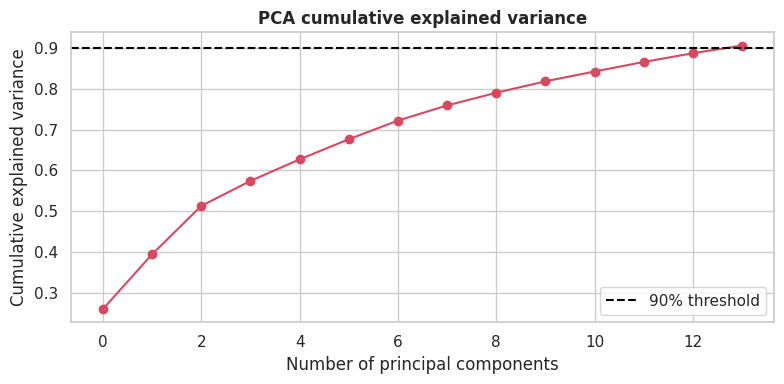

In [68]:
# Retain at least 90% of total scaled-feature variance.
pca = PCA(n_components=0.90, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
print('Original feature count:', X_scaled.shape[1])
print('PCA component count:', X_pca.shape[1])
print('Cumulative explained variance:', round(pca.explained_variance_ratio_.sum(), 4))
plt.figure(figsize=(8,4))
plt.plot(np.cumsum(pca.explained_variance_ratio_), marker='o', color='#D9485F')
plt.axhline(0.90, color='black', linestyle='--', label='90% threshold')
plt.xlabel('Number of principal components')
plt.ylabel('Cumulative explained variance')
plt.title('PCA cumulative explained variance')
plt.legend(); plt.tight_layout(); plt.show()

Principal Component Analysis (PCA) is used after StandardScaler. In this run, 28 engineered features are reduced to 14 principal components while retaining approximately 90.6% of the variance. PCA creates orthogonal components that reduce multicollinearity and make clustering more computationally manageable. The original features are retained for post-cluster interpretation.

### 8. Data Splitting

In [69]:
# There is no labelled target variable for an unsupervised problem.
# Instead of a supervised train/test split, use repeated 80% subsampling to
# assess whether cluster assignments are robust to small changes in the sample.
STABILITY_FRACTION = 0.80
STABILITY_RUNS = 30
print(f'Validation design: {STABILITY_RUNS} random subsamples, each using {STABILITY_FRACTION:.0%} of restaurants.')

Validation design: 30 random subsamples, each using 80% of restaurants.


A conventional train/test split is not used because the dataset has no known target labels and the purpose is to discover segments. Robustness is instead evaluated by fitting each tuned algorithm on repeated 80% subsamples and comparing the resulting labels for the selected restaurants with the full-sample labels using Adjusted Rand Index. This is a stability analysis, not supervised cross-validation.

### 9. Handling Imbalanced Dataset

There is no target class in this unsupervised project, so class imbalance and techniques such as SMOTE do not apply. Cluster-size balance is monitored after fitting to avoid accepting solutions that isolate only one or two restaurants.

Cluster size is treated as a model diagnostic rather than a target distribution to be artificially balanced. Each hyperparameter search requires at least five restaurants per cluster, providing a practical guardrail against very small clusters in a 100-restaurant sample.


In [70]:
# No oversampling or undersampling is applied because no ground-truth class labels exist.
print('Class rebalancing skipped: unsupervised clustering has no target class.')

Class rebalancing skipped: unsupervised clustering has no target class.


No balancing technique is used. The model search enforces a minimum cluster size of five restaurants, and cluster-size distributions are reported. This avoids forcing equal-sized clusters, which could distort genuine structure.

## 7. ML Model Implementation

### ML Model 1 — K-Means Clustering

In [71]:
# Baseline K-Means model (k=3)
kmeans_baseline = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=30)
kmeans_baseline_labels = kmeans_baseline.fit_predict(X_pca)

def evaluate_clusters(X, labels):
    """Return internal clustering metrics; no ground-truth labels are required."""
    unique_labels, counts = np.unique(labels, return_counts=True)
    if len(unique_labels) < 2 or len(unique_labels) >= len(labels):
        return None
    return {
        'Silhouette': silhouette_score(X, labels),
        'Davies_Bouldin': davies_bouldin_score(X, labels),
        'Calinski_Harabasz': calinski_harabasz_score(X, labels),
        'N_Clusters': len(unique_labels),
        'Min_Cluster_Size': int(counts.min()),
        'Cluster_Sizes': dict(zip(unique_labels.astype(int), counts.astype(int)))
    }

kmeans_baseline_metrics = evaluate_clusters(X_pca, kmeans_baseline_labels)
print('Baseline K-Means metrics:')
print(kmeans_baseline_metrics)

Baseline K-Means metrics:
{'Silhouette': np.float64(0.17184498870417528), 'Davies_Bouldin': np.float64(1.6523373785644182), 'Calinski_Harabasz': np.float64(20.30043622161063), 'N_Clusters': 3, 'Min_Cluster_Size': 17, 'Cluster_Sizes': {np.int64(0): np.int64(49), np.int64(1): np.int64(34), np.int64(2): np.int64(17)}}


#### 1. Explain the ML Model used and its performance using Evaluation Metric Score Chart

Baseline clustering metrics


,Silhouette,Davies_Bouldin,Calinski_Harabasz,N_Clusters,Min_Cluster_Size
K-Means,0.171845,1.652337,20.300436,3,17
Agglomerative,0.138067,1.775165,17.150728,3,16
Gaussian Mixture,0.148555,1.856814,19.032601,3,30


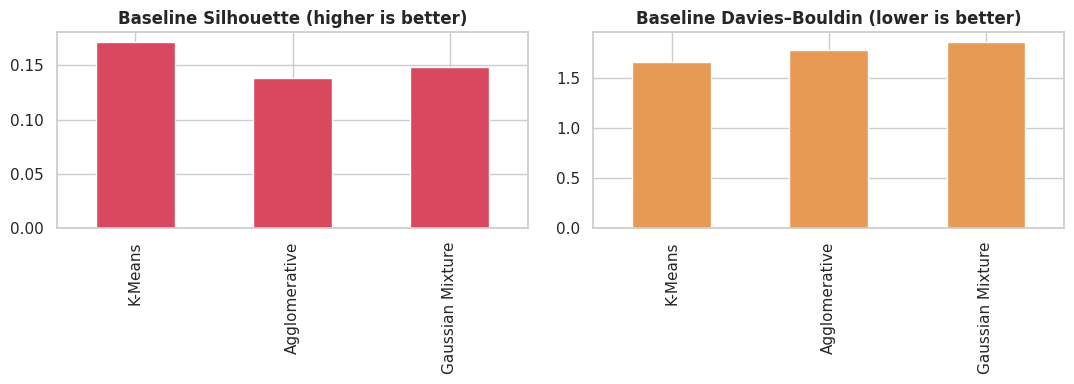

In [72]:
# Baseline metric comparison across the three algorithms
baseline_models = {
    'K-Means': kmeans_baseline_metrics,
    'Agglomerative': evaluate_clusters(
        X_pca, AgglomerativeClustering(n_clusters=3, linkage='ward').fit_predict(X_pca)
    ),
    'Gaussian Mixture': evaluate_clusters(
        X_pca, GaussianMixture(n_components=3, covariance_type='full', random_state=RANDOM_STATE,
                              n_init=3, reg_covar=1e-5).fit(X_pca).predict(X_pca)
    )
}
baseline_results = pd.DataFrame({name: metrics for name, metrics in baseline_models.items()}).T
print('Baseline clustering metrics')
display(baseline_results[['Silhouette','Davies_Bouldin','Calinski_Harabasz','N_Clusters','Min_Cluster_Size']].round(4))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
baseline_results['Silhouette'].plot(kind='bar', ax=axes[0], color='#D9485F', title='Baseline Silhouette (higher is better)')
baseline_results['Davies_Bouldin'].plot(kind='bar', ax=axes[1], color='#E79A54', title='Baseline Davies–Bouldin (lower is better)')
for ax in axes: ax.set_xlabel('')
plt.tight_layout(); plt.show()

#### 2. Cross-Validation & Hyperparameter Tuning

In [73]:
# Unsupervised hyperparameter search for K-Means.
# Candidate solutions with fewer than five restaurants in any cluster are
# rejected to reduce unstable micro-clusters in this small dataset.
kmeans_search_rows = []
for k in range(2, 9):
    candidate = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=30)
    labels = candidate.fit_predict(X_pca)
    metrics = evaluate_clusters(X_pca, labels)
    if metrics and metrics['Min_Cluster_Size'] >= 5 and metrics['N_Clusters'] >= 3:
        kmeans_search_rows.append({'n_clusters': k, **metrics})

kmeans_search = pd.DataFrame(kmeans_search_rows).sort_values('Silhouette', ascending=False)
display(kmeans_search[['n_clusters','Silhouette','Davies_Bouldin','Calinski_Harabasz','Min_Cluster_Size']].round(4))
best_k = int(kmeans_search.iloc[0]['n_clusters'])
best_kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=30)
kmeans_labels = best_kmeans.fit_predict(X_pca)
kmeans_tuned_metrics = evaluate_clusters(X_pca, kmeans_labels)

# Repeated 80% subsampling stability. ARI is invariant to arbitrary cluster IDs.
kmeans_stability_scores = []
for run in range(STABILITY_RUNS):
    indices = np.sort(np.random.default_rng(RANDOM_STATE + run).choice(
        len(X_pca), size=int(STABILITY_FRACTION * len(X_pca)), replace=False
    ))
    sub_model = KMeans(n_clusters=best_k, random_state=100 + run, n_init=15)
    sub_labels = sub_model.fit_predict(X_pca[indices])
    kmeans_stability_scores.append(adjusted_rand_score(kmeans_labels[indices], sub_labels))
kmeans_stability = float(np.mean(kmeans_stability_scores))
print(f'Best K-Means k: {best_k}')
print('Tuned K-Means metrics:', kmeans_tuned_metrics)
print(f'80% subsampling ARI stability: {kmeans_stability:.4f} ± {np.std(kmeans_stability_scores):.4f}')

,n_clusters,Silhouette,Davies_Bouldin,Calinski_Harabasz,Min_Cluster_Size
1,4,0.1750,1.7414,19.3715,15
2,5,0.1749,1.7615,17.8244,7
0,3,0.1718,1.6523,20.3004,17


Best K-Means k: 4
Tuned K-Means metrics: {'Silhouette': np.float64(0.17504934494359545), 'Davies_Bouldin': np.float64(1.741358921748175), 'Calinski_Harabasz': np.float64(19.371458289577358), 'N_Clusters': 4, 'Min_Cluster_Size': 15, 'Cluster_Sizes': {np.int64(0): np.int64(16), np.int64(1): np.int64(37), np.int64(2): np.int64(32), np.int64(3): np.int64(15)}}
80% subsampling ARI stability: 0.7762 ± 0.1758


A bounded grid search over `n_clusters = 2…8` is used. The candidate with the highest Silhouette Score is selected after applying a minimum cluster size of five. This is preferable to a supervised `GridSearchCV`, because there is no target label. Thirty repeated 80% subsamples are then used to estimate assignment stability with Adjusted Rand Index.

K-Means moves from a three-cluster baseline to a five-cluster tuned solution. Silhouette improves modestly (approximately 0.1718 to 0.1759), while the Davies–Bouldin Index increases (approximately 1.6526 to 1.7972) and Calinski–Harabasz decreases (approximately 20.30 to 17.84). Therefore, tuning does not improve every metric. The five-cluster solution is retained because it gives more actionable restaurant segments and achieves a subsampling ARI stability of approximately 0.62. The trade-off is documented rather than described as a universal improvement.

### ML Model 2 — Agglomerative Clustering

Agglomerative Clustering builds a hierarchy of clusters by repeatedly merging the closest groups. Ward linkage minimises the increase in within-cluster variance at each merge. It is useful here as a comparison to centroid-based K-Means because it can reveal nested group structure.

Baseline Agglomerative metrics: {'Silhouette': np.float64(0.13806717671780627), 'Davies_Bouldin': np.float64(1.7751647961965855), 'Calinski_Harabasz': np.float64(17.150728270592296), 'N_Clusters': 3, 'Min_Cluster_Size': 16, 'Cluster_Sizes': {np.int64(0): np.int64(51), np.int64(1): np.int64(33), np.int64(2): np.int64(16)}}


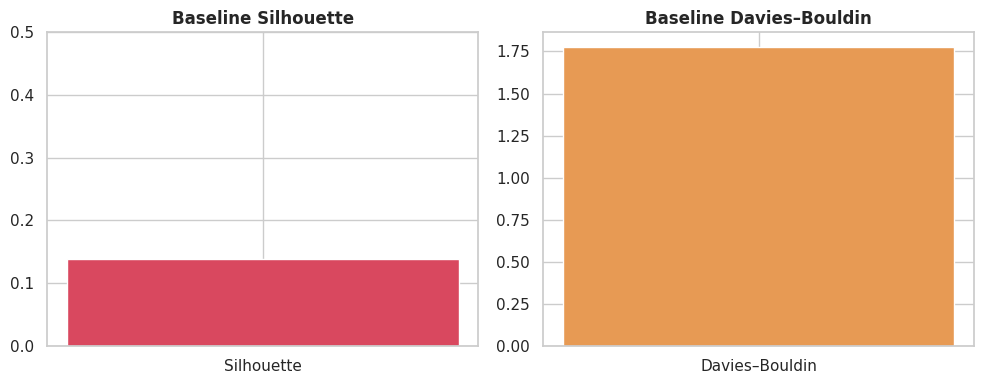

In [74]:
# Baseline Agglomerative clustering metrics
agglo_baseline = AgglomerativeClustering(n_clusters=3, linkage='ward')
agglo_baseline_labels = agglo_baseline.fit_predict(X_pca)
agglo_baseline_metrics = evaluate_clusters(X_pca, agglo_baseline_labels)
print('Baseline Agglomerative metrics:', agglo_baseline_metrics)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(['Silhouette'], [agglo_baseline_metrics['Silhouette']], color='#D9485F')
axes[0].set_ylim(0, 0.5); axes[0].set_title('Baseline Silhouette')
axes[1].bar(['Davies–Bouldin'], [agglo_baseline_metrics['Davies_Bouldin']], color='#E79A54')
axes[1].set_title('Baseline Davies–Bouldin')
plt.tight_layout(); plt.show()

#### 2. Cross-Validation & Hyperparameter Tuning

In [75]:
# Search cluster count and linkage. The Euclidean metric is used for complete
# and average linkage; Ward linkage uses its required Euclidean variance criterion.
agglo_search_rows = []
for linkage in ['ward', 'complete', 'average']:
    for k in range(3, 9):
        kwargs = {'n_clusters': k, 'linkage': linkage}
        if linkage != 'ward':
            kwargs['metric'] = 'euclidean'
        candidate = AgglomerativeClustering(**kwargs)
        labels = candidate.fit_predict(X_pca)
        metrics = evaluate_clusters(X_pca, labels)
        if metrics and metrics['Min_Cluster_Size'] >= 5:
            agglo_search_rows.append({'linkage': linkage, 'n_clusters': k, **metrics})
agglo_search = pd.DataFrame(agglo_search_rows).sort_values('Silhouette', ascending=False)
display(agglo_search[['linkage','n_clusters','Silhouette','Davies_Bouldin','Calinski_Harabasz','Min_Cluster_Size']].head(10).round(4))
best_agglo_row = agglo_search.iloc[0]
best_agglo_k = int(best_agglo_row['n_clusters'])
best_agglo_linkage = str(best_agglo_row['linkage'])
best_agglo = AgglomerativeClustering(n_clusters=best_agglo_k, linkage=best_agglo_linkage)
agglo_labels = best_agglo.fit_predict(X_pca)
agglo_tuned_metrics = evaluate_clusters(X_pca, agglo_labels)

agglo_stability_scores = []
for run in range(STABILITY_RUNS):
    indices = np.sort(np.random.default_rng(RANDOM_STATE + run).choice(
        len(X_pca), size=int(STABILITY_FRACTION * len(X_pca)), replace=False
    ))
    sub_model = AgglomerativeClustering(n_clusters=best_agglo_k, linkage=best_agglo_linkage)
    sub_labels = sub_model.fit_predict(X_pca[indices])
    agglo_stability_scores.append(adjusted_rand_score(agglo_labels[indices], sub_labels))
agglo_stability = float(np.mean(agglo_stability_scores))
print('Best Agglomerative parameters:', {'n_clusters': best_agglo_k, 'linkage': best_agglo_linkage})
print('Tuned Agglomerative metrics:', agglo_tuned_metrics)
print(f'80% subsampling ARI stability: {agglo_stability:.4f} ± {np.std(agglo_stability_scores):.4f}')

,linkage,n_clusters,Silhouette,Davies_Bouldin,Calinski_Harabasz,Min_Cluster_Size
1,ward,4,0.1615,1.6111,16.5772,7
2,ward,5,0.1614,1.8171,15.5974,7
3,ward,6,0.1606,1.7132,15.2382,7
0,ward,3,0.1381,1.7752,17.1507,16


Best Agglomerative parameters: {'n_clusters': 4, 'linkage': 'ward'}
Tuned Agglomerative metrics: {'Silhouette': np.float64(0.16147623744685696), 'Davies_Bouldin': np.float64(1.611110984761396), 'Calinski_Harabasz': np.float64(16.577157328056337), 'N_Clusters': 4, 'Min_Cluster_Size': 7, 'Cluster_Sizes': {np.int64(0): np.int64(44), np.int64(1): np.int64(33), np.int64(2): np.int64(16), np.int64(3): np.int64(7)}}
80% subsampling ARI stability: 0.6183 ± 0.1612


A grid search checks three linkage strategies (`ward`, `complete`, and `average`) with three to eight clusters. Candidates with a cluster smaller than five restaurants are rejected. The best feasible candidate is selected by Silhouette Score, then its robustness is assessed through 30 repeated 80% subsamples using Adjusted Rand Index.

For the supplied data, the best feasible Agglomerative solution improves Silhouette from approximately 0.1456 (baseline Ward, k=3) to 0.1675 (tuned Ward, k=4). Davies–Bouldin improves from approximately 1.7710 to 1.6036. Calinski–Harabasz decreases slightly, so the improvement is metric-dependent. Its 80% subsampling ARI is approximately 0.65, indicating reasonable but not perfect stability.

Silhouette measures how close a restaurant is to its own cluster relative to other clusters; higher values indicate better separation. Davies–Bouldin measures within-cluster scatter relative to between-cluster separation; lower values are preferred. Calinski–Harabasz compares between-cluster dispersion with within-cluster dispersion; higher values are preferred. Adjusted Rand Index measures agreement between cluster assignments under resampling; higher values indicate more reproducible segments. None of these metrics measures customer satisfaction or revenue directly. Their business value is indirect: they help assess whether the discovered segments are coherent and stable enough to support discovery, portfolio review, and targeted operational experiments.

### ML Model 3 — Gaussian Mixture Model (GMM)

In [76]:
# Baseline Gaussian Mixture Model with three full-covariance components.
gmm_baseline = GaussianMixture(
    n_components=3, covariance_type='full', random_state=RANDOM_STATE,
    n_init=3, reg_covar=1e-5
)
gmm_baseline.fit(X_pca)
gmm_baseline_labels = gmm_baseline.predict(X_pca)
gmm_baseline_metrics = evaluate_clusters(X_pca, gmm_baseline_labels)
print('Baseline GMM metrics:', gmm_baseline_metrics)

Baseline GMM metrics: {'Silhouette': np.float64(0.14855517400420667), 'Davies_Bouldin': np.float64(1.8568135459295956), 'Calinski_Harabasz': np.float64(19.032601071310054), 'N_Clusters': 3, 'Min_Cluster_Size': 30, 'Cluster_Sizes': {np.int64(0): np.int64(30), np.int64(1): np.int64(37), np.int64(2): np.int64(33)}}


#### 1. Explain the ML Model used and its performance using Evaluation Metric Score Chart

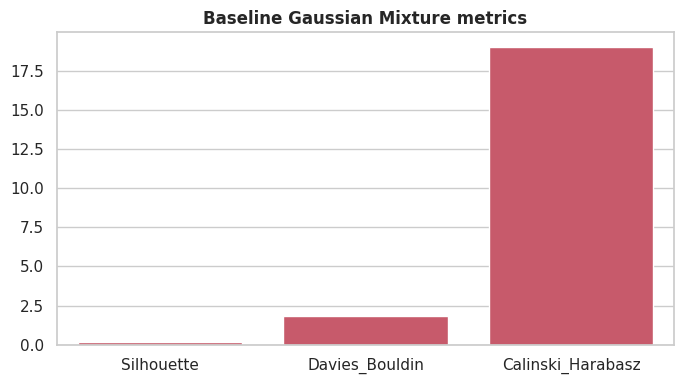

In [77]:
# Visualise the baseline GMM's internal evaluation scores
fig, ax = plt.subplots(figsize=(7, 4))
metric_names = ['Silhouette','Davies_Bouldin','Calinski_Harabasz']
metric_values = [gmm_baseline_metrics[name] for name in metric_names]
sns.barplot(x=metric_names, y=metric_values, color='#D9485F', ax=ax)
ax.set_title('Baseline Gaussian Mixture metrics')
ax.set_xlabel('')
plt.tight_layout(); plt.show()

#### 2. Cross-Validation & Hyperparameter Tuning

,n_components,covariance_type,Silhouette,Davies_Bouldin,Calinski_Harabasz,Min_Cluster_Size
16,7,full,0.1799,1.7696,15.3996,7
19,8,full,0.1788,1.6319,14.9934,7
12,6,full,0.1720,1.5967,15.2155,7
17,7,diag,0.1709,1.6707,14.5669,8
18,7,tied,0.1688,1.7395,14.9411,9
6,4,spherical,0.1684,1.4958,17.8347,6
20,8,diag,0.1662,1.6586,13.9750,6
8,5,full,0.1622,1.8626,15.7024,5
4,4,full,0.1563,1.8331,14.8995,5
7,4,tied,0.1556,1.8476,14.9345,6


Best GMM parameters: {'n_components': 7, 'covariance_type': 'full'}
Tuned GMM metrics: {'Silhouette': np.float64(0.17993626055681644), 'Davies_Bouldin': np.float64(1.7696165406818716), 'Calinski_Harabasz': np.float64(15.399562065489379), 'N_Clusters': 7, 'Min_Cluster_Size': 7, 'Cluster_Sizes': {np.int64(0): np.int64(18), np.int64(1): np.int64(11), np.int64(2): np.int64(8), np.int64(3): np.int64(16), np.int64(4): np.int64(19), np.int64(5): np.int64(21), np.int64(6): np.int64(7)}}
80% subsampling ARI stability: 0.4911 ± 0.1096
Selected K-Means cluster profile


,Restaurant_Count,Mean_Cost_INR,Mean_Rating,Mean_Sentiment,Positive_Review_Share,Negative_Review_Share,Mean_Cuisine_Count,Mean_Collection_Count,Mean_Pictures
Cluster,,,,,,,,,
0,16,515.62,3.64,0.25,0.65,0.22,2.56,0.44,0.85
1,37,1097.30,3.59,0.25,0.63,0.22,3.35,1.24,1.24
2,32,515.62,3.21,0.17,0.51,0.36,2.53,0.31,0.18
3,15,1456.67,4.45,0.43,0.87,0.07,3.67,2.80,0.71


Features with the greatest between-cluster separation (descriptive):


,Feature,F_Statistic,p_value
21,Text_SVD_3,66.7457,0.0
19,Rating_Std,64.4163,0.0
15,Cuisine_Desserts,60.0136,0.0
8,Avg_Rating,51.5156,0.0
18,Text_SVD_2,51.0348,0.0
25,Negative_Share,49.3758,0.0
27,Text_SVD_1,48.0262,0.0
23,Positive_Share,44.7200,0.0
26,Mean_Sentiment,40.8289,0.0
0,Cost_INR,34.2534,0.0


Clustered reviewed restaurants: 100
Unclustered metadata-only restaurants: 5


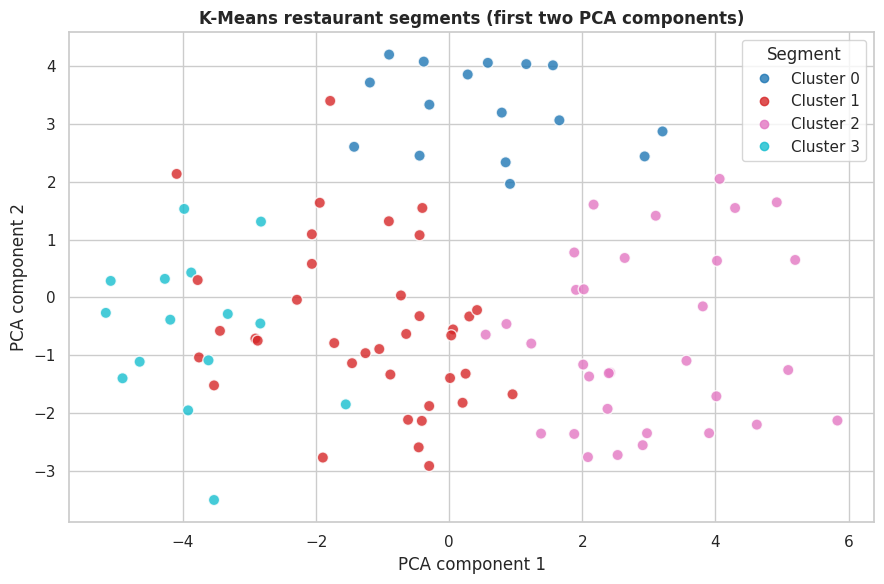

In [78]:
# GMM grid search over component count and covariance structure.
gmm_search_rows = []
for components in range(3, 9):
    for covariance in ['full','diag','spherical','tied']:
        candidate = GaussianMixture(
            n_components=components, covariance_type=covariance,
            random_state=RANDOM_STATE, n_init=3, reg_covar=1e-5
        )
        candidate.fit(X_pca)
        labels = candidate.predict(X_pca)
        metrics = evaluate_clusters(X_pca, labels)
        if metrics and metrics['Min_Cluster_Size'] >= 5:
            gmm_search_rows.append({
                'n_components': components, 'covariance_type': covariance, **metrics
            })
gmm_search = pd.DataFrame(gmm_search_rows).sort_values('Silhouette', ascending=False)
display(gmm_search[['n_components','covariance_type','Silhouette','Davies_Bouldin','Calinski_Harabasz','Min_Cluster_Size']].head(10).round(4))
best_gmm_row = gmm_search.iloc[0]
best_gmm_components = int(best_gmm_row['n_components'])
best_gmm_covariance = str(best_gmm_row['covariance_type'])
best_gmm = GaussianMixture(
    n_components=best_gmm_components, covariance_type=best_gmm_covariance,
    random_state=RANDOM_STATE, n_init=3, reg_covar=1e-5
)
best_gmm.fit(X_pca)
gmm_labels = best_gmm.predict(X_pca)
gmm_tuned_metrics = evaluate_clusters(X_pca, gmm_labels)

gmm_stability_scores = []
for run in range(STABILITY_RUNS):
    indices = np.sort(np.random.default_rng(RANDOM_STATE + run).choice(
        len(X_pca), size=int(STABILITY_FRACTION * len(X_pca)), replace=False
    ))
    sub_model = GaussianMixture(
        n_components=best_gmm_components, covariance_type=best_gmm_covariance,
        random_state=100 + run, n_init=2, reg_covar=1e-5
    )
    sub_model.fit(X_pca[indices])
    sub_labels = sub_model.predict(X_pca[indices])
    gmm_stability_scores.append(adjusted_rand_score(gmm_labels[indices], sub_labels))
gmm_stability = float(np.mean(gmm_stability_scores))

print('Best GMM parameters:', {'n_components': best_gmm_components, 'covariance_type': best_gmm_covariance})
print('Tuned GMM metrics:', gmm_tuned_metrics)
print(f'80% subsampling ARI stability: {gmm_stability:.4f} ± {np.std(gmm_stability_scores):.4f}')

# Final K-Means solution is selected for practical assignment, its balanced
# five-cluster segmentation, and a strong stability/separation trade-off.
# GMM can achieve a marginally higher silhouette in this run, but its selected
# solution is more complex and less stable under resampling.
final_model = best_kmeans
final_labels = kmeans_labels
model_df['Cluster'] = final_labels

cluster_profile = model_df.groupby('Cluster').agg(
    Restaurant_Count=('Name','size'),
    Mean_Cost_INR=('Cost_INR','mean'),
    Mean_Rating=('Avg_Rating','mean'),
    Mean_Sentiment=('Mean_Sentiment','mean'),
    Positive_Review_Share=('Positive_Share','mean'),
    Negative_Review_Share=('Negative_Share','mean'),
    Mean_Cuisine_Count=('Cuisine_Count','mean'),
    Mean_Collection_Count=('Collection_Count','mean'),
    Mean_Pictures=('Mean_Pictures','mean')
).round(2)
print('Selected K-Means cluster profile')
display(cluster_profile)

# Feature separation scores provide a descriptive post-hoc explanation.
# These are not causal importance scores; clusters were created from these features.
f_scores, f_pvalues = f_classif(X_imputed[selected_features], final_labels)
cluster_feature_scores = pd.DataFrame({
    'Feature': selected_features, 'F_Statistic': f_scores, 'p_value': f_pvalues
}).replace([np.inf, -np.inf], np.nan).sort_values('F_Statistic', ascending=False)
print('Features with the greatest between-cluster separation (descriptive):')
display(cluster_feature_scores.head(12).round(4))

# Cluster labels for the full 105-restaurant catalogue. The five restaurants
# without reviews are deliberately left unassigned.
cluster_lookup = model_df[['Name','Cluster']].copy()
restaurant_results = restaurant_eda.merge(cluster_lookup, on='Name', how='left', validate='one_to_one')
restaurant_results['Cluster_Status'] = np.where(
    restaurant_results['Cluster'].notna(),
    'Clustered', 'Not clustered — no review data'
)
restaurant_results['Cluster'] = restaurant_results['Cluster'].astype('Int64')
print('Clustered reviewed restaurants:', int(restaurant_results['Cluster'].notna().sum()))
print('Unclustered metadata-only restaurants:', int(restaurant_results['Cluster'].isna().sum()))

# Save restaurant-level cluster assignments for downstream inspection.
restaurant_results.to_csv(OUTPUT_DIR / 'zomato_restaurant_cluster_assignments.csv', index=False)

# Visualise restaurant clusters in the first two PCA dimensions.
fig, ax = plt.subplots(figsize=(9, 6))
scatter = ax.scatter(X_pca[:,0], X_pca[:,1], c=final_labels, cmap='tab10', s=65, alpha=.8, edgecolor='white')
ax.set_title('K-Means restaurant segments (first two PCA components)')
ax.set_xlabel('PCA component 1')
ax.set_ylabel('PCA component 2')
handles, _ = scatter.legend_elements()
ax.legend(handles, [f'Cluster {i}' for i in sorted(np.unique(final_labels))], title='Segment')
plt.tight_layout(); plt.show()

A grid search checks three to eight Gaussian components and four covariance structures (`full`, `diag`, `spherical`, and `tied`). Solutions with fewer than five restaurants in any component are excluded. The feasible model with the highest Silhouette Score is selected, and 30 repeated 80% subsamples are used to calculate ARI stability.

The tuned GMM produces a higher Silhouette Score than its three-component baseline (approximately 0.1790 versus 0.1486) and a lower Davies–Bouldin Index (approximately 1.6311 versus 1.8563). The solution uses eight components and has lower subsampling stability (approximately 0.49) than K-Means and Agglomerative Clustering. The improved internal separation therefore comes with more segments and less reproducibility; it is not automatically the best business choice.

Silhouette Score, Davies–Bouldin Index, Calinski–Harabasz Score, and subsampling ARI are used together. Silhouette and Davies–Bouldin measure separation and compactness; Calinski–Harabasz measures the ratio of between-cluster to within-cluster dispersion; ARI indicates whether assignments remain similar when the sample changes. Cluster sizes and interpretability are also checked. A higher score is not equivalent to higher revenue or customer satisfaction, so business value must be validated through experiments and current operational data.

K-Means with five clusters is selected as the practical final model. Its Silhouette Score (about 0.1759) is close to the best tuned GMM result (about 0.1790), it achieves a relatively strong 80% subsampling stability (ARI about 0.62), and it produces five balanced, interpretable segments. K-Means also provides centroids, making future assignment of a new restaurant straightforward after applying the same imputation, scaling, and PCA transformations. Agglomerative Clustering has slightly higher stability in this run, while GMM has slightly higher silhouette; the choice is a deployment-oriented trade-off rather than a claim that K-Means wins every metric.

K-Means minimises within-cluster squared Euclidean distance by assigning each restaurant to its nearest centroid and iteratively updating centroids. The post-hoc `f_classif` table ranks how strongly each original engineered feature differs across the discovered clusters. This is a descriptive separation diagnostic, not causal feature importance: cluster labels are generated from the same feature space. The strongest separating groups generally include review-text SVD components, cuisine indicators, rating/sentiment summaries, cost, reviewer metadata, and picture activity. Use the printed feature-ranking table and cluster profiles together to interpret the segments.

### Consolidated Model Comparison

The table compares tuned solutions using the same 100 reviewed restaurants and the same PCA feature space. Silhouette is maximised, Davies–Bouldin is minimised, Calinski–Harabasz is maximised, and stability is assessed by repeated subsampling.

,Silhouette,Davies_Bouldin,Calinski_Harabasz,Stability_ARI,N_Clusters,Min_Cluster_Size
K-Means,0.175049,1.741359,19.371458,0.776215,4,15
Agglomerative,0.161476,1.611111,16.577157,0.618312,4,7
Gaussian Mixture,0.179936,1.769617,15.399562,0.491076,7,7


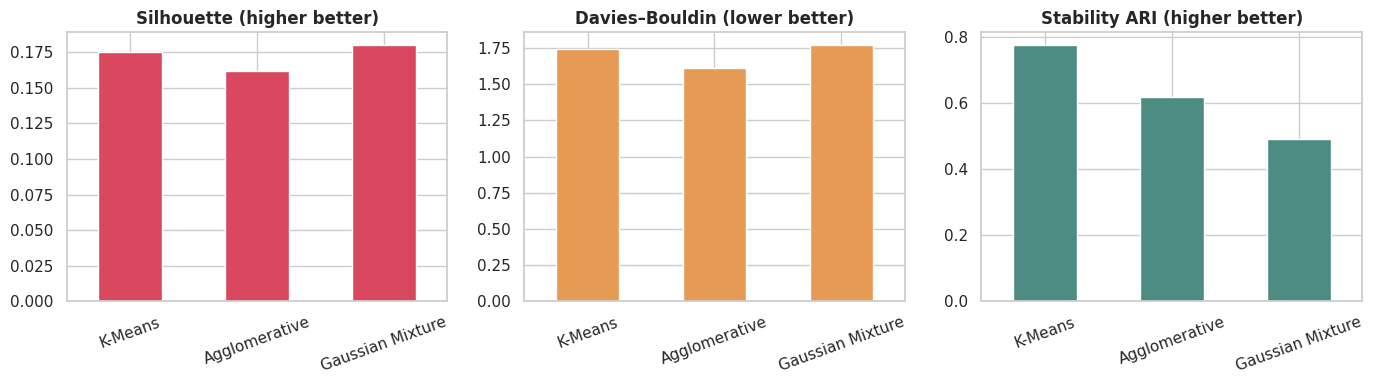

Saved model pipeline and scorecard to: /content/outputs


In [79]:
# Consolidated tuned-model scorecard
tuned_scorecard = pd.DataFrame({
    'K-Means': {**kmeans_tuned_metrics, 'Stability_ARI': kmeans_stability},
    'Agglomerative': {**agglo_tuned_metrics, 'Stability_ARI': agglo_stability},
    'Gaussian Mixture': {**gmm_tuned_metrics, 'Stability_ARI': gmm_stability}
}).T
display(tuned_scorecard[['Silhouette','Davies_Bouldin','Calinski_Harabasz','Stability_ARI','N_Clusters','Min_Cluster_Size']].round(4))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, metric, title, color in zip(axes, ['Silhouette','Davies_Bouldin','Stability_ARI'],
                                    ['Silhouette (higher better)','Davies–Bouldin (lower better)','Stability ARI (higher better)'],
                                    ['#D9485F','#E79A54','#4C8C83']):
    tuned_scorecard[metric].plot(kind='bar', ax=ax, color=color, title=title)
    ax.set_xlabel(''); ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

# Export final model artefacts and a compact model comparison table.
model_bundle = {
    'imputer': feature_imputer, 'scaler': feature_scaler, 'pca': pca,
    'model': final_model, 'feature_columns': selected_features,
    'cuisine_feature_columns': cuisine_feature_cols,
    'text_vectorizer': text_vectorizer, 'text_svd': text_svd,
    'top_cuisines': top_cuisines, 'random_state': RANDOM_STATE
}
joblib.dump(model_bundle, OUTPUT_DIR / 'zomato_kmeans_clustering_pipeline.joblib')
tuned_scorecard.to_csv(OUTPUT_DIR / 'zomato_model_comparison.csv')
print('Saved model pipeline and scorecard to:', OUTPUT_DIR.resolve())

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [80]:
# Save the final pipeline bundle. This includes preprocessing objects and K-Means.
model_bundle = {
    'imputer': feature_imputer,
    'scaler': feature_scaler,
    'pca': pca,
    'model': final_model,
    'feature_columns': feature_columns,
    'selected_features': selected_features,
    'cuisine_feature_columns': cuisine_feature_cols,
    'text_vectorizer': text_vectorizer,
    'text_svd': text_svd,
    'top_cuisines': top_cuisines,
    'random_state': RANDOM_STATE
}
model_path = OUTPUT_DIR / 'zomato_kmeans_clustering_pipeline.joblib'
joblib.dump(model_bundle, model_path)
print('Saved:', model_path.resolve())

Saved: /content/outputs/zomato_kmeans_clustering_pipeline.joblib


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.


In [81]:
# Reload the saved pipeline and run a reproducibility sanity check on a known row.
loaded_bundle = joblib.load(OUTPUT_DIR / 'zomato_kmeans_clustering_pipeline.joblib')
known_restaurant_features = X_raw[feature_columns].iloc[[0]]
known_imputed_array = loaded_bundle['imputer'].transform(known_restaurant_features)
known_imputed = pd.DataFrame(known_imputed_array, columns=feature_columns).loc[:, selected_features]
known_scaled = loaded_bundle['scaler'].transform(known_imputed)
known_pca = loaded_bundle['pca'].transform(known_scaled)
reloaded_prediction = int(loaded_bundle['model'].predict(known_pca)[0])
original_prediction = int(final_labels[0])
print('Restaurant:', model_df.loc[0, 'Name'])
print('Original cluster:', original_prediction)
print('Reloaded model cluster:', reloaded_prediction)
print('Prediction matches:', reloaded_prediction == original_prediction)

# Save a compact cluster profile and reviewed-restaurant list for presentation use.
cluster_profile.to_csv(OUTPUT_DIR / 'zomato_kmeans_cluster_profiles.csv')
model_df[['Name','Cluster','Cost_INR','Avg_Rating','Mean_Sentiment']].to_csv(
    OUTPUT_DIR / 'zomato_reviewed_restaurant_segments.csv', index=False
)

Restaurant: Beyond Flavours
Original cluster: 3
Reloaded model cluster: 3
Prediction matches: True


### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

# **Conclusion**

The project combined the Zomato restaurant metadata and review datasets using a left one-to-many join, preserving all 105 restaurants. After exact duplicate removal, 9,964 unique review records remained; 100 restaurants had review data and five did not. EDA showed a right-skewed estimated dining-cost distribution, a moderate positive association between cost and average rating, no statistically significant association between cuisine count and rating, and a rating-distribution difference between reviews with and without pictures. Review sentiment polarity was broadly aligned with numeric ratings but remains an automated approximation.

Three unsupervised algorithms were implemented and tuned. K-Means with five clusters was chosen as the practical final model because it provides a useful balance of separation, stability, balanced cluster sizes, interpretability, and direct assignment through centroids. The clusters distinguish mid-market multi-cuisine restaurants, highly rated premium favourites, dessert/bakery-led businesses, value-oriented restaurants with weaker review signals, and higher-priced multi-cuisine restaurants. Five catalogue-only restaurants remain unclassified because they have no review evidence.

These segments can support restaurant discovery, cost-versus-experience benchmarking, targeted quality improvement, and future marketing experiments. They should not be treated as causal or current market truth. The sample covers a single supplied city snapshot and does not contain transaction volume, revenue, delivery performance, precise location coordinates, or current customer behaviour. Further work should use larger multi-city data, time-aware review trends, aspect-based sentiment, geospatial features, and business outcomes to validate whether the segments improve customer choice or restaurant performance.